In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import Spectral_Preprocessing as sp

from argparse import ArgumentParser, Namespace
from scipy import stats

In [140]:
parser = ArgumentParser()
parser.add_argument("--range-ir-1", dest= "wn_range_ir_1", default = (948,1860))
parser.add_argument("--range-ir-2", dest= "wn_range_ir_2", default = (2698,3002))

parser.add_argument("--range-min-ir", dest= "range_min_ir", type = int, default = 400)
parser.add_argument("--range-max-ir", dest= "range_max_ir", type = int, default = 4000)
parser.add_argument("--interpolate-interval-ir", dest = "interpolate_interval_ir", type = int, default = 1) 

parser.add_argument("--finger-print-exl", dest= "finger_print_exl", type = bool, default = False)
parser.add_argument("--trans-chip", dest= "trans_chip", type = bool, default = False)

parser.add_argument("--background-rule-ir", dest= "background_rule", type = str, default = 'mean')
parser.add_argument("--threshold-mean-intensity-ir", dest= "ths_mean_int_ir", type = float, default = 0)
parser.add_argument("--threshold-total-variation-intensity-ir", dest= "ths_tot_var_int_ir", type = float, default = 0)

parser.add_argument("--range-min-raman", dest= "range_min_raman", type = float, default = 400)
parser.add_argument("--range-max-raman", dest= "range_max_raman", type = float, default = 4000)
parser.add_argument("--interpolate-interval-raman", dest = "interpolate_interval_raman", type = float, default = 1) 

parser.add_argument("--rubberband", dest="rubberband", action="store_true", default=False,)
parser.add_argument("--minmax", dest="minmax", action="store_true", default=False,)
parser.add_argument("--no-interpolate", dest = "no_interpolate", action="store_true", default = False)
parser.add_argument("--nitrogen-calibration", dest="nitrogen_calibration", action="store_true", default=True,)
parser.add_argument("--si-peak", dest= "si_peak", type = float, default = 520)

parser.add_argument("--smooth", dest = "smooth", type = int, default = 0)
parser.add_argument("--baseline", dest = "baseline", type = int, default = 5)

###Sample Code #1: Specify IR and Raman interpolation intervals along with min & max values
args: Namespace = parser.parse_args([]) ###Do not alter this section.
###PLEASE TYPE IN YOUR ARGUMENTS HERE
args.wn_range_ir_1 = (947.0,1862.0)#(980, 1800)#(947,3000)
args.wn_range_ir_2 = (2695.0,3000)#(2720, 2970)#(3001,3010)
args.range_min_ir = 675.0#947# #674.9918 ###enter an integer
args.range_max_ir = 4000.0#3000# #3999.809 ###enter an integer [max value is not included]
args.interpolate_interval_ir = 2 #1.929 ###enter an integer
args.finger_print_exl = False
args.trans_chip = True
args.background_rule = 'total_var'
args.ths_mean_int_ir = 0.043
args.ths_tot_var_int_ir = 0.4543#0.59

args.range_min_raman = 355 #.555542 ###enter an integer or float #530
args.range_max_raman = 3500 #3895.935059 ##enter an integer or float [max value is not included] 
args.interpolate_interval_raman = 2.0 #168021680216802 ###enter an integer or float

args.rubberband = 'specy'#'als'#'specy' ###True for rubberband, False for iModPoly
args.minmax = 'snv' ###False for SVT normalization, True for minmax
args.no_interpolate = False ###use sample code 2 if using True for this option.
args.nitrogen_calibration = False ##True for calibration, False for no calibration.


# Mixed-Std

In [230]:
si_peak_cal = pd.read_excel(open('multiview_hqi_cp/data_new/20240715_mIRageRaman_CalibrationLog.xlsx', 'rb'),
                  sheet_name='Si peak for PTIR files')

args.si_peak = np.array(si_peak_cal.query('Sample =="MPs + Standards"').iloc[:,2]) ###enter an integer or float

labels = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='Other cc data and sort')# ,header=0,index_col=0

labels = labels.iloc[:,[0,9,10,11,12]].set_index('Overall ID')
labels = labels.rename({'Manual PTIR':'polymer_ptir',
                        'Manual Raman':'polymer_raman',
                        'Manual overall':'polymer'}, axis=1)

IR_spectra = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='PTIR spectra',header=0)#,index_col=0
IR_spectra = IR_spectra.rename({1:'1.1','1.1':1},axis=1)
idx_file_change = np.where(IR_spectra.iloc[1,:] == 'X value [cmâ\x81»Â¹]')[0]

df_list_ir = []
for i in range(idx_file_change.shape[0]):
    idx = IR_spectra.columns[idx_file_change[i]]
    if i == idx_file_change.shape[0] - 1:
        df = IR_spectra.iloc[:,idx_file_change[i]:]
    else:
        df = IR_spectra.iloc[:,idx_file_change[i]:(idx_file_change[i+1])]
        
    df = df.rename({idx:'wavenumber'},axis=1).set_index('wavenumber')
    df = df.drop(df.index[[0,1]], axis=0).T
    df = df.merge(labels.iloc[:,2:3], left_index=True, right_index=True)
    df = df.reset_index(drop=True)
    df['map_x'] = 0
    df['map_y'] = 0
    df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
    df_list_ir.append(df)
    

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_38096/1857402771.py:33: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_38096/1857402771.py:33: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_38096/1857402771.py:33: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting 

In [231]:
Raman_spectra = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='Raman spectra',header=0)#,index_col=0
Raman_spectra = Raman_spectra.rename({1:'1.1','1.1':1},axis=1)
idx_file_change = np.where(Raman_spectra.iloc[1,:] == 'X value [cmâ\x81»Â¹]')[0]

df_list_raman = []
for i in range(idx_file_change.shape[0]):
    idx = Raman_spectra.columns[idx_file_change[i]]
    if i == idx_file_change.shape[0] - 1:
        #df_list.append(Raman_spectra.iloc[:,idx_file_change[i]:])
        df = Raman_spectra.iloc[:,idx_file_change[i]:]
    else:
        #df_list.append(Raman_spectra.iloc[:,idx_file_change[i]:(idx_file_change[i+1])])
        df = Raman_spectra.iloc[:,idx_file_change[i]:(idx_file_change[i+1])]
        
    df = df.rename({idx:'wavenumber'},axis=1).set_index('wavenumber')
    df = df.drop(df.index[[0,1]], axis=0).T
    df = df.merge(labels.iloc[:,2:3], left_index=True, right_index=True)
    df = df.reset_index(drop=True)
    df['map_x'] = 0
    df['map_y'] = 0
    df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
    df_list_raman.append(df)
    

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_38096/3677326041.py:22: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_38096/3677326041.py:22: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_38096/3677326041.py:22: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting 

In [232]:
df_list = [[x,y] for x, y in zip(df_list_ir, df_list_raman)]

In [117]:
df_list[0][0]

wavenumber,948,950,952,954,956,958,960,962,964,966,...,2992,2994,2996,2998,3000,3002,3004,polymer,map_x,map_y
0,1.899016,-0.671095,0.136044,0.577573,1.404857,0.053826,0.737176,0.344171,-0.205893,-0.533032,...,-0.743061,-2.546740,-1.892269,0.026270,-2.642579,-2.907217,1.649865,sucrose,0,0
1,3.996607,3.902390,0.650212,1.092958,1.831030,0.627314,-0.361043,-0.265881,-0.142119,0.802052,...,1.733984,-0.513897,3.322600,2.397753,6.439721,3.247530,3.913688,sucrose,0,0
2,0.420234,0.405571,-1.305963,0.534316,-0.290385,-0.345198,0.106074,-0.494494,-0.245375,0.095924,...,-0.698479,-3.865273,-4.415198,-3.775720,-5.972148,0.596711,1.970475,sucrose,0,0
3,-0.842039,-1.988625,-1.566544,-0.080558,0.927192,0.117710,-0.964287,-0.610649,-0.131191,0.266596,...,0.922640,1.098155,2.199029,-1.224075,-3.044912,-3.525475,-5.252574,sucrose,0,0
4,-3.198784,-4.409377,-2.965626,-2.199942,-2.652162,-2.238916,-1.710158,-0.966759,-0.855568,-0.774887,...,-4.111774,0.435604,-0.715400,-4.349504,-5.872221,-5.409883,-10.128578,sucrose,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122,-0.253807,-2.939493,-0.693387,-1.701105,-0.385052,0.124194,-0.179697,0.307913,-0.515743,-0.564902,...,-2.834989,-3.859174,0.149049,2.069275,-2.928668,-3.071951,-5.070527,sucrose,0,0
123,1.615703,0.154453,0.282804,0.651789,0.412208,-0.388511,-0.868549,-0.579452,0.146884,0.729101,...,1.102763,0.501138,1.340874,1.510421,4.341640,6.616840,5.356522,sucrose,0,0
124,0.321900,0.217786,-0.668124,0.141940,-0.478270,-0.115045,-0.769759,-0.743788,-1.111176,-0.403467,...,-0.695685,-1.043819,1.758977,-2.888818,1.559166,2.501029,-5.140357,sucrose,0,0
125,-3.595290,-0.756453,0.874332,0.035669,-0.303781,-1.189617,-0.452256,-0.687806,0.331921,-0.167423,...,-3.100420,-0.188356,-1.298356,1.232718,-2.629274,-10.180428,-2.783068,sucrose,0,0


In [233]:
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = df_list, transpose = True)


/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:187: RuntimeWarning: invalid value encountered in divide
  return (x - x.mean()) / x.std()


In [234]:
preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['polymer'] = label_list

preposs_data_raman['polymer_raman'] = np.array(labels['polymer_raman'])
preposs_data_raman['polymer_ir'] = np.array(labels['polymer_ptir'])
preposs_data_raman['comments'] = np.array(labels['Notes'])

preposs_data_raman['id'] = list(range(1,preposs_data_raman.shape[0]+1))
preposs_data_raman.to_csv('multiview_hqi_cp/processed_data_new/data_raman_mix_std_rebecca_specy.csv')
#preposs_data_raman.to_csv('multiview_hqi_cp/processed_data_new/data_raman_mix_std_rebecca_pre_cal.csv')
preposs_data_raman

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3495.0,3497.0,3499.0,map_x,map_y,polymer,polymer_raman,polymer_ir,comments,id
0,0.112233,0.096241,0.085584,0.079057,0.105876,0.113547,0.084871,0.055533,0.025771,-0.020289,...,-0.455759,-0.455759,-0.455759,0,0,AS,AS,AS,NaN,1
1,-0.036364,-0.003905,0.096631,0.210578,0.303234,0.377557,0.417076,0.395734,0.335352,0.192672,...,-0.567356,-0.567356,-0.567356,0,0,SCR,SCR,SCR,NaN,2
2,0.529223,0.539355,0.500111,0.463886,0.588023,0.699873,0.788398,0.776077,0.699070,0.530545,...,-0.620195,-0.620195,-0.620195,0,0,LOW,LOW,LOW,NaN,3
3,-0.034300,-0.187928,-0.008984,0.234328,0.360538,0.417276,0.342134,0.276071,0.215829,0.217909,...,-0.633416,-0.633416,-0.633416,0,0,LOW,LOW,LOW,NaN,4
4,0.202750,0.114899,0.390851,0.723894,0.777361,0.839203,0.916944,0.946876,0.946143,0.789394,...,-0.598984,-0.598984,-0.598984,0,0,LOW,LOW,LOW,NaN,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
424,0.053610,0.053610,0.053610,0.053610,0.053610,0.053610,0.053610,0.053610,0.053610,0.053610,...,-0.232610,-0.233835,-0.233368,0,0,LDPE,LDPE,LDPE,NaN,425
425,3.383905,3.383905,3.383905,3.383905,3.383905,3.383905,3.383905,3.383905,3.383905,3.383905,...,-0.569295,-0.569295,-0.569295,0,0,LOW,LOW,LOW,NaN,426
426,2.618839,2.618839,2.618839,2.618839,2.618839,2.618839,2.618839,2.618839,2.618839,2.618839,...,-0.580355,-0.580355,-0.580355,0,0,SCR,SCR,UNS,NOT ENOUGH IDENTIFIABLE PEAKS IN PTIR,427
427,0.059170,0.059170,0.059170,0.059170,0.059170,0.059170,0.059170,0.059170,0.059170,0.059170,...,-0.257682,-0.257682,-0.257682,0,0,LDPE,LDPE,LDPE,NaN,428


In [235]:
np.unique(preposs_data_raman['polymer_ir'])

array(['AS', 'LDPE', 'LOW', 'MIX', 'PP', 'PSL', 'SCR', 'SN', 'UNS'],
      dtype=object)

In [236]:
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['polymer'] = label_list

preposs_data_ir['polymer_raman'] = np.array(labels['polymer_raman'])
preposs_data_ir['polymer_ir'] = np.array(labels['polymer_ptir'])
preposs_data_ir['comments'] = np.array(labels['Notes'])

preposs_data_ir['id'] = list(range(1,preposs_data_ir.shape[0]+1))#pol_table.iloc[ids,:].reset_index(drop=True)
preposs_data_ir['background'] = ir_bg_label
preposs_data_ir.to_csv('multiview_hqi_cp/processed_data_new/data_ir_mix_std_rebecca.csv')
preposs_data_ir

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer,polymer_raman,polymer_ir,comments,id,background
0,-0.828293,-0.758405,-0.726251,-0.765111,-0.770808,-0.728753,-0.727293,-0.757429,-0.730070,-0.732946,...,2.214848,2.194427,0,0,AS,AS,AS,NaN,1,no_background
1,-0.163192,-0.074564,-0.230509,-0.292448,-0.220771,0.011111,0.144867,-0.239115,-0.418914,-0.141851,...,0.964838,0.918447,0,0,SCR,SCR,SCR,NaN,2,no_background
2,-0.438056,0.933417,2.150888,2.177525,0.860700,0.452132,-0.315118,-1.185153,-0.967110,-0.651419,...,1.018770,2.725846,0,0,LOW,LOW,LOW,NaN,3,background
3,1.638889,0.455108,-0.441436,-0.560524,-1.166359,-1.748550,-1.613215,-1.766743,-1.025346,0.141626,...,1.408004,2.597168,0,0,LOW,LOW,LOW,NaN,4,no_background
4,0.205335,1.241631,0.875970,-0.050083,-0.290827,0.486683,0.731929,0.275573,0.824066,0.533222,...,0.827264,-0.205617,0,0,LOW,LOW,LOW,NaN,5,background
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
424,-0.373516,-0.376575,-0.377634,-0.371173,-0.377284,-0.377095,-0.369783,-0.372860,-0.377227,-0.376942,...,0.011794,-0.051611,0,0,LDPE,LDPE,LDPE,NaN,425,no_background
425,0.292612,1.338728,0.671795,-0.383573,0.609145,1.037086,0.503721,-0.399152,-0.734338,-0.374284,...,6.442037,1.190010,0,0,LOW,LOW,LOW,NaN,426,background
426,-0.069403,-0.123240,-0.263766,-0.277517,-0.033042,0.268466,0.312587,0.225755,-0.073730,-0.459947,...,2.018124,2.487920,0,0,SCR,SCR,UNS,NOT ENOUGH IDENTIFIABLE PEAKS IN PTIR,427,no_background
427,-0.275073,-0.273339,-0.274917,-0.276279,-0.275879,-0.275556,-0.274775,-0.275425,-0.276779,-0.276364,...,-0.234312,-0.243280,0,0,LDPE,LDPE,LDPE,NaN,428,no_background


# Mixed

In [141]:
si_peak_cal = pd.read_excel(open('multiview_hqi_cp/data_new/20240715_mIRageRaman_CalibrationLog.xlsx', 'rb'),
                  sheet_name='Si peak for PTIR files')

args.si_peak = np.array(si_peak_cal.query('Sample =="MPs only"').iloc[:,2]) ###enter an integer or float

labels = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='Other cc data and sort')# ,header=0,index_col=0

#labels = labels.iloc[:,[0,9,10,11,12]].set_index('Overall ID')
#labels = labels.rename({'Manual overall':'polymer'}, axis=1)

labels = labels.iloc[:,[0,9,10,11,12]].set_index('Overall ID')
labels = labels.rename({'Manual PTIR':'polymer_ptir',
                        'Manual Raman':'polymer_raman',
                        'Manual overall':'polymer'}, axis=1)

IR_spectra = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='PTIR spectra',header=0)#,index_col=0

IR_spectra = IR_spectra.rename({1:'1.1','1.1':1},axis=1)

idx_file_change = np.where(IR_spectra.iloc[1,:] == 'X value [cmâ\x81»Â¹]')[0]

df_list_ir = []
for i in range(idx_file_change.shape[0]):
    idx = IR_spectra.columns[idx_file_change[i]]
    if i == idx_file_change.shape[0] - 1:
        df = IR_spectra.iloc[:,idx_file_change[i]:]
    else:
        df = IR_spectra.iloc[:,idx_file_change[i]:(idx_file_change[i+1])]
        
    df = df.rename({idx:'wavenumber'},axis=1).set_index('wavenumber')
    df = df.drop(df.index[[0,1]], axis=0).T
    df = df.merge(labels.iloc[:,2:3], left_index=True, right_index=True)
    df = df.reset_index(drop=True)
    df['map_x'] = 0
    df['map_y'] = 0
    df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
    df_list_ir.append(df)

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_42528/3970740773.py:38: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_42528/3970740773.py:38: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_42528/3970740773.py:38: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of 

In [142]:
Raman_spectra = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='Raman spectra',header=0)#,index_col=0
Raman_spectra = Raman_spectra.rename({1:'1.1','1.1':1},axis=1)
idx_file_change = np.where(Raman_spectra.iloc[1,:] == 'X value [cmâ\x81»Â¹]')[0]

df_list_raman = []
for i in range(idx_file_change.shape[0]):
    idx = Raman_spectra.columns[idx_file_change[i]]
    if i == idx_file_change.shape[0] - 1:
        #df_list.append(Raman_spectra.iloc[:,idx_file_change[i]:])
        df = Raman_spectra.iloc[:,idx_file_change[i]:]
    else:
        #df_list.append(Raman_spectra.iloc[:,idx_file_change[i]:(idx_file_change[i+1])])
        df = Raman_spectra.iloc[:,idx_file_change[i]:(idx_file_change[i+1])]
        
    df = df.rename({idx:'wavenumber'},axis=1).set_index('wavenumber')
    df = df.drop(df.index[[0,1]], axis=0).T
    df = df.merge(labels.iloc[:,2:3], left_index=True, right_index=True)
    df = df.reset_index(drop=True)
    df['map_x'] = 0
    df['map_y'] = 0
    df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
    df_list_raman.append(df)
    

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_42528/3355034535.py:22: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_42528/3355034535.py:22: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_42528/3355034535.py:22: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of 

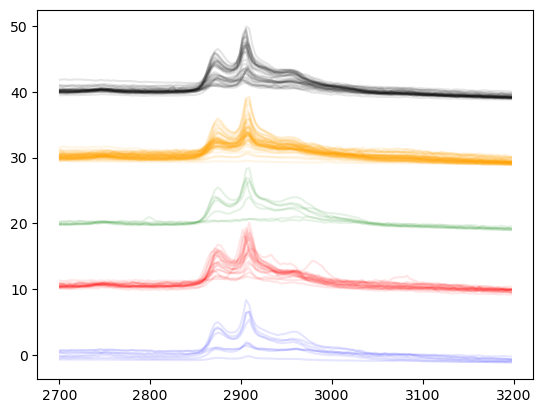

In [239]:
colors = ['b', 'r', 'g', 'orange', 'black']
for i in range(5):
    df = df_list_raman[i].query('polymer =="LDPE"').iloc[:,:-4]
    df = (df - np.nanmean(df, 1)[:,None])/np.nanstd(df, 1)[:,None]
    
    idx_si_peak = np.where(np.logical_and(df.columns > 2700,
               df.columns < 3200))[0] 
    
    
    plt.plot(df.iloc[:,idx_si_peak].T+i*10, c=colors[i], alpha=.1)

In [143]:
args.si_peak #= np.array([520]*5)

array([544.83, 544.83, 544.83, 544.83, 544.83])

In [144]:
df_list = [[x,y] for x, y in zip(df_list_ir, df_list_raman)]

In [145]:
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, nitro_cal_list, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = df_list, transpose = True)


In [74]:
preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['polymer'] = label_list

preposs_data_raman['polymer_raman'] = np.array(labels['polymer_raman'])
preposs_data_raman['polymer_ir'] = np.array(labels['polymer_ptir'])
preposs_data_raman['comments'] = np.array(labels['Notes'])

preposs_data_raman['id'] = list(range(1,preposs_data_raman.shape[0]+1))#pol_table.iloc[ids,:].reset_index(drop=True)
#preposs_data_raman.to_csv('multiview_hqi_cp/processed_data_new/data_raman_mix_rebecca_specy.csv')
preposs_data_raman

,329.0,331.0,333.0,335.0,337.0,339.0,341.0,343.0,345.0,347.0,...,3849.0,3851.0,3853.0,map_x,map_y,polymer,polymer_raman,polymer_ir,comments,id
0,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,...,-0.583607,-0.583607,-0.583607,0,0,PSL,PSL,PSL,NaN,1
1,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,...,-0.658985,-0.658985,-0.658985,0,0,PP,PP,PP,NaN,2
2,-0.254248,-0.264209,-0.265573,-0.279294,-0.289455,-0.286406,-0.296179,-0.318997,-0.350046,-0.383215,...,-0.696035,-0.696035,-0.696035,0,0,UNS,UNS,UNS,MAY BE PP?,3
3,-0.376174,-0.376174,-0.376174,-0.376174,-0.376174,-0.376174,-0.376174,-0.376174,-0.376174,-0.376174,...,-0.296070,-0.286940,-0.239488,0,0,LDPE,UNS,LDPE,NaN,4
4,-0.257706,-0.267612,-0.278368,-0.284629,-0.290218,-0.294079,-0.293335,-0.287904,-0.279389,-0.270306,...,-0.420593,-0.420593,-0.420593,0,0,PP,PP,PP,NaN,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
670,-0.775577,-0.775577,-0.775577,-0.775577,-0.741222,-0.592812,-0.424479,-0.235875,-0.131816,-0.053324,...,-0.775577,-0.711173,-0.602546,0,0,LOW,LOW,LOW,NaN,671
671,-0.468589,-0.468589,-0.468589,-0.468589,-0.468589,-0.468589,-0.434244,-0.364954,-0.334882,-0.317924,...,-0.186797,-0.228683,-0.262909,0,0,LDPE,LDPE,LDPE,NaN,672
672,-0.709063,-0.518469,-0.247394,-0.392074,-0.453778,-0.193359,0.043707,0.257015,0.357833,0.422559,...,-0.709063,-0.461665,-0.044392,0,0,LOW,LOW,LOW,NaN,673
673,-0.734488,-0.622003,-0.462020,-0.515124,-0.511538,-0.295835,-0.120942,0.012429,0.076339,0.116033,...,-0.734488,-0.734488,-0.734488,0,0,LOW,LOW,LOW,NaN,674


In [64]:
lower_range_raman_1 = 700
upper_range_raman_1 = 1850
lower_range_raman_2 = 2750
upper_range_raman_2 = 3500

wn_raman = np.array(preposs_data_raman.columns[:-7])

idx_raman = list(np.logical_or(np.logical_and(wn_raman >lower_range_raman_1,
                           wn_raman <upper_range_raman_1
                           ),
                 np.logical_and(wn_raman >lower_range_raman_2,
                           wn_raman <upper_range_raman_2
                           ))) + [False]*7

In [67]:
preposs_data_raman.query('id == 53').loc[:,idx_raman].to_csv('multiview_hqi_cp/results_final/20251209/truncated_id_mix_53.csv')


In [80]:
preposs_data_raman.query('id == 53').iloc[:,:-7].to_csv('multiview_hqi_cp/results_final/20251209/not_truncated_id_mix_53.csv')

In [53]:
preposs_data_raman.query('id == 53').iloc[:,164:-579].to_csv('multiview_hqi_cp/results_final/20251209/not_truncated_id_mix_53.csv')


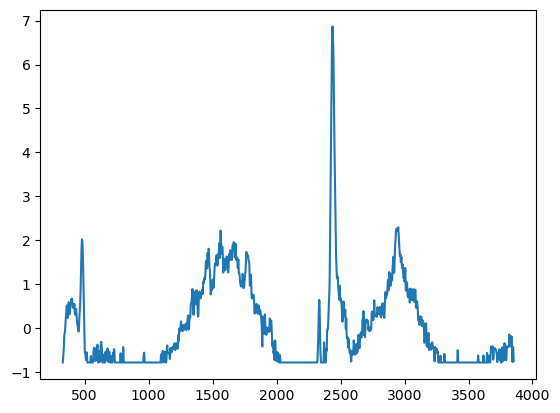

In [79]:
_ = plt.plot(preposs_data_raman.query('id == 53').iloc[:,:-7].T)

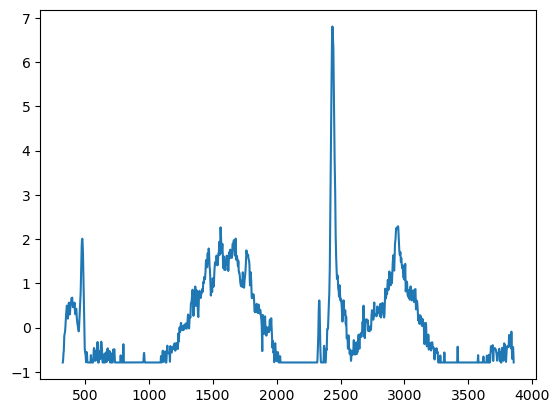

In [51]:
_ = plt.plot(preposs_data_raman.query('id == 53').iloc[:,164:-579].T)

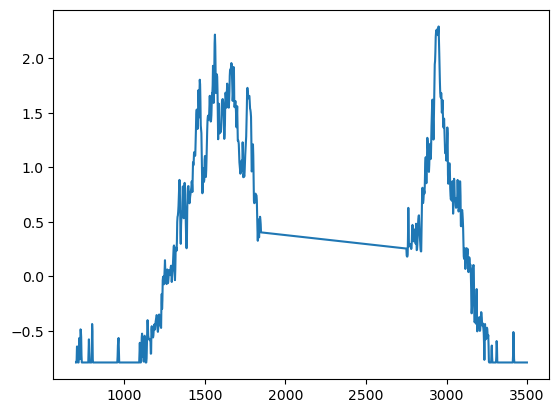

In [66]:
_ = plt.plot(preposs_data_raman.query('id == 53').loc[:,idx_raman].T)

In [244]:
idx_si_peak = np.where(np.logical_and(preposs_data_raman.columns[:-7] > 400,
               preposs_data_raman.columns[:-7] < 650))[0]


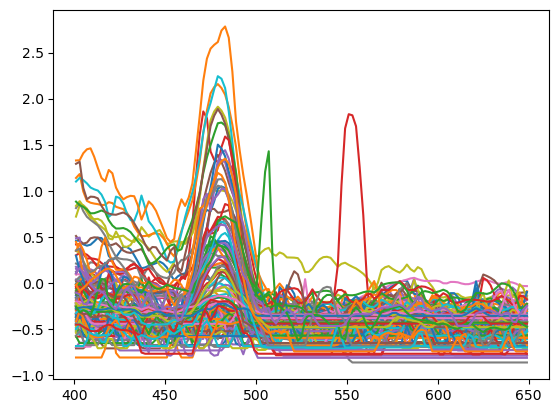

In [245]:
_ = plt.plot(preposs_data_raman.query('polymer == "LDPE"').iloc[:,:-4].iloc[:,idx_si_peak].T)

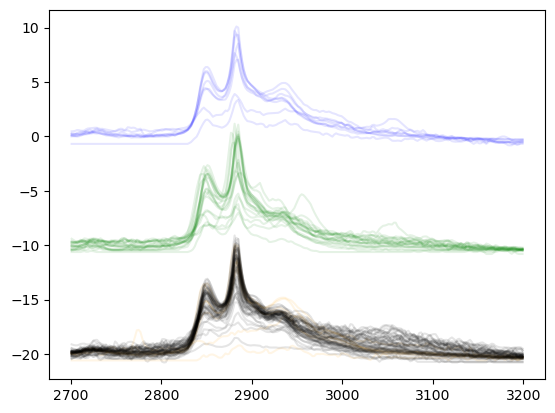

In [246]:
idx_si_peak = np.where(np.logical_and(preposs_data_raman.columns[:-7] > 2700,
               preposs_data_raman.columns[:-7] < 3200))[0]


_ = plt.plot(preposs_data_raman.query('polymer == "LDPE" and id <= 128').iloc[:,:-4].iloc[:,idx_si_peak].T, c='b', alpha = .1)

_ = plt.plot(preposs_data_raman.query('polymer == "LDPE" and id > 128 and id <=194').iloc[:,:-4].iloc[:,idx_si_peak].T-10, c='g', alpha = .1)

_ = plt.plot(preposs_data_raman.query('polymer == "LDPE" and id > 194 and id <=280').iloc[:,:-4].iloc[:,idx_si_peak].T-20, c='orange', alpha = .1)

_ = plt.plot(preposs_data_raman.query('polymer == "LDPE" and id > 280 and id <=485').iloc[:,:-4].iloc[:,idx_si_peak].T-20, c='black', alpha = .1)


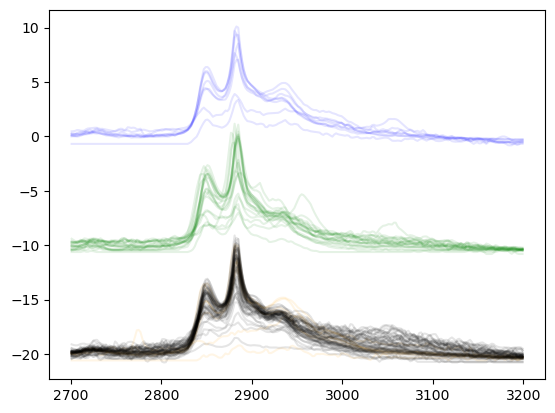

In [247]:
idx_si_peak = np.where(np.logical_and(preposs_data_raman.columns[:-7] > 2700,
               preposs_data_raman.columns[:-7] < 3200))[0]


_ = plt.plot(preposs_data_raman.query('polymer == "LDPE" and id <= 128').iloc[:,:-4].iloc[:,idx_si_peak].T, c='b', alpha = .1)

_ = plt.plot(preposs_data_raman.query('polymer == "LDPE" and id > 128 and id <=194').iloc[:,:-4].iloc[:,idx_si_peak].T-10, c='g', alpha = .1)

_ = plt.plot(preposs_data_raman.query('polymer == "LDPE" and id > 194 and id <=280').iloc[:,:-4].iloc[:,idx_si_peak].T-20, c='orange', alpha = .1)

_ = plt.plot(preposs_data_raman.query('polymer == "LDPE" and id > 280 and id <=485').iloc[:,:-4].iloc[:,idx_si_peak].T-20, c='black', alpha = .1)


In [146]:
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['polymer'] = label_list

preposs_data_ir['polymer_raman'] = np.array(labels['polymer_raman'])
preposs_data_ir['polymer_ir'] = np.array(labels['polymer_ptir'])
preposs_data_ir['comments'] = np.array(labels['Notes'])

preposs_data_ir['id'] = list(range(1,preposs_data_raman.shape[0]+1))#pol_table.iloc[ids,:].reset_index(drop=True)
preposs_data_ir['background'] = ir_bg_label
#preposs_data_ir.to_csv('multiview_hqi_cp/processed_data_new/data_ir_mix_rebecca.csv')
preposs_data_ir

,947.0,949.0,951.0,953.0,955.0,957.0,959.0,961.0,963.0,965.0,...,2997.0,2999.0,map_x,map_y,polymer,polymer_raman,polymer_ir,comments,id,background
0,1.381304,-0.321190,-1.399821,-0.754624,0.047611,-0.662788,-1.975969,-1.058899,-0.283173,0.422939,...,-7.194226,-3.141266,0,0,PSL,PSL,PSL,NaN,1,no_background
1,-0.275034,-0.140918,-0.028468,-0.442281,-0.900012,-0.770696,-0.345235,-0.218663,-0.439496,-0.519468,...,3.185891,3.709826,0,0,PP,PP,PP,NaN,2,no_background
2,-1.117204,-1.282067,-1.248800,-1.046725,-1.175471,-1.258840,-1.181821,-1.072187,-1.069365,-1.101480,...,-0.749214,-1.067833,0,0,UNS,UNS,UNS,MAY BE PP?,3,no_background
3,-0.388694,-0.347744,-0.280477,-0.268921,-0.277817,-0.264561,-0.255803,-0.250538,-0.254363,-0.252427,...,-0.018097,-0.095828,0,0,LDPE,UNS,LDPE,NaN,4,no_background
4,-1.466212,-1.426050,-1.466587,-1.503375,-1.347396,-1.213361,-1.229344,-1.241277,-1.173829,-1.149696,...,-0.817031,-1.029717,0,0,PP,PP,PP,NaN,5,no_background
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
670,-6.615387,-5.458630,-5.297329,-3.350092,-2.218324,-1.247371,-0.316688,-2.285319,-2.452254,-1.680995,...,-4.636429,-0.118452,0,0,LOW,LOW,LOW,NaN,671,no_background
671,-7.740214,-3.617461,-2.779202,-6.859290,-4.347813,-0.601009,-0.988306,-1.325733,-0.914218,-1.125244,...,2.531431,3.781298,0,0,LDPE,LDPE,LDPE,NaN,672,no_background
672,6.027931,5.430764,5.150775,6.777771,5.533987,2.144248,0.733792,-0.067311,0.613193,1.232287,...,6.519636,11.179684,0,0,LOW,LOW,LOW,NaN,673,no_background
673,3.095619,-1.097962,-0.761959,4.483787,3.956178,1.833251,0.399330,0.408640,0.394907,0.627254,...,6.434443,8.870143,0,0,LOW,LOW,LOW,NaN,674,no_background


In [139]:
preposs_data_ir.query('id==53').iloc[:,:-8].to_csv('multiview_hqi_cp/results_final/20251209/truncated_id_mix_53_ir.csv')


In [149]:
preposs_data_ir.query('id==53').iloc[:,:-8].to_csv('multiview_hqi_cp/results_final/20251209/not_truncated_id_mix_53_ir.csv')


In [127]:
np.mean(preposs_data_ir.query('id==53').iloc[:,:-8].to_numpy()), np.std(preposs_data_ir.query('id==53').iloc[:,:-8].to_numpy())


(3.459312248101754e-17, 0.9999999999999999)

In [138]:
np.mean(preposs_data_ir.query('id==53').iloc[:,:-8].to_numpy()), np.std(preposs_data_ir.query('id==53').iloc[:,:-8].to_numpy())


(-3.320293157757477e-17, 1.0)

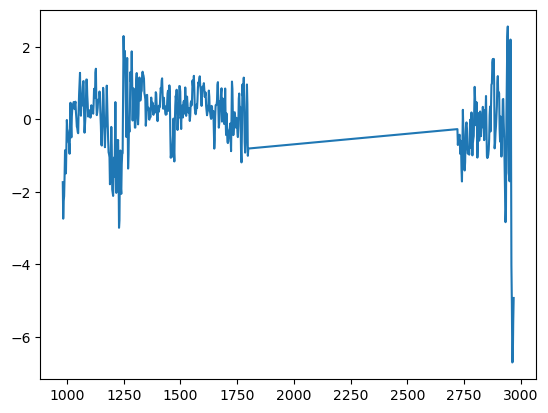

In [137]:
_ = plt.plot(preposs_data_ir.query('id==53').iloc[:,:-8].T)

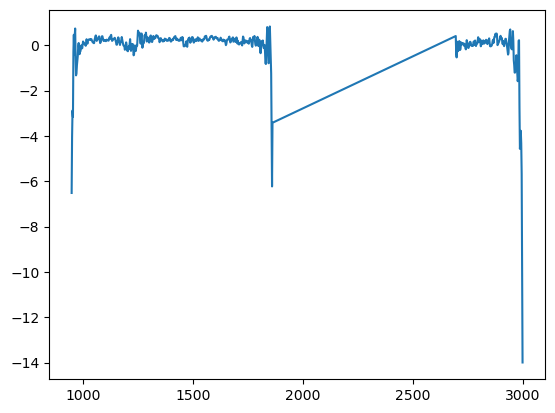

In [148]:
_ = plt.plot(preposs_data_ir.query('id==53').iloc[:,:-8].T)

# Ambient

In [3]:
si_peak_cal = pd.read_excel(open('multiview_hqi_cp/data_new/20240715_mIRageRaman_CalibrationLog.xlsx', 'rb'),
                  sheet_name='Si peak for PTIR files')

args.si_peak = np.array(si_peak_cal.query('Sample =="Ambient + MPs"').iloc[:,2]) ###enter an integer or float

labels = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240716_AmbientandMPsv1_RP_mIRage_allccdata_manualsort_firstlookplots2.xlsx', 'rb'),
                  sheet_name='Other cc data and sort')# ,header=0,index_col=0

labels = labels.iloc[:,[0,9,10,11,12]].set_index('Overall ID')
#labels = labels.rename({'Manual overall':'polymer'}, axis=1)

labels = labels.rename({'Manual PTIR':'polymer_ptir',
                        'Manual Raman':'polymer_raman',
                        'Manual overall':'polymer'}, axis=1)


IR_spectra = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240716_AmbientandMPsv1_RP_mIRage_allccdata_manualsort_firstlookplots2.xlsx', 'rb'),
                  sheet_name='PTIR spectra',header=0)#,index_col=0

IR_spectra = IR_spectra.rename({1:'1.1','1.1':1},axis=1)

idx_file_change = np.where(IR_spectra.iloc[1,:] == 'X value [cmâ\x81»Â¹]')[0]

df_list_ir = []
for i in range(idx_file_change.shape[0]):
    idx = IR_spectra.columns[idx_file_change[i]]
    if i == idx_file_change.shape[0] - 1:
        df = IR_spectra.iloc[:,idx_file_change[i]:]
    else:
        df = IR_spectra.iloc[:,idx_file_change[i]:(idx_file_change[i+1])]
        
    df = df.rename({idx:'wavenumber'},axis=1).set_index('wavenumber')
    df = df.drop(df.index[[0,1]], axis=0).T
    df = df.merge(labels.iloc[:,2:3], left_index=True, right_index=True)
    df = df.reset_index(drop=True)
    df['map_x'] = 0
    df['map_y'] = 0
    df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
    df_list_ir.append(df)

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_26263/1014422594.py:38: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_26263/1014422594.py:38: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])


In [250]:
Raman_spectra = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240716_AmbientandMPsv1_RP_mIRage_allccdata_manualsort_firstlookplots2.xlsx', 'rb'),
                  sheet_name='Raman spectra',header=0)#,index_col=0
Raman_spectra = Raman_spectra.rename({1:'1.1','1.1':1},axis=1)
idx_file_change = np.where(Raman_spectra.iloc[1,:] == 'X value [cmâ\x81»Â¹]')[0]

df_list_raman = []
for i in range(idx_file_change.shape[0]):
    idx = Raman_spectra.columns[idx_file_change[i]]
    if i == idx_file_change.shape[0] - 1:
        #df_list.append(Raman_spectra.iloc[:,idx_file_change[i]:])
        df = Raman_spectra.iloc[:,idx_file_change[i]:]
    else:
        #df_list.append(Raman_spectra.iloc[:,idx_file_change[i]:(idx_file_change[i+1])])
        df = Raman_spectra.iloc[:,idx_file_change[i]:(idx_file_change[i+1])]
        
    df = df.rename({idx:'wavenumber'},axis=1).set_index('wavenumber')
    df = df.drop(df.index[[0,1]], axis=0).T
    df = df.merge(labels.iloc[:,2:3], left_index=True, right_index=True)
    df = df.reset_index(drop=True)
    df['map_x'] = 0
    df['map_y'] = 0
    df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
    df_list_raman.append(df)
    

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_38096/1546692708.py:22: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_38096/1546692708.py:22: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])


In [251]:
df_list = [[x,y] for x, y in zip(df_list_ir, df_list_raman)]

In [252]:
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = df_list, transpose = True)


/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:187: RuntimeWarning: invalid value encountered in divide
  return (x - x.mean()) / x.std()
/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:187: RuntimeWarning: invalid value encountered in divide
  return (x - x.mean()) / x.std()


In [253]:
labels

,polymer_ptir,polymer_raman,polymer,Notes
Overall ID,,,,
1,PSL,PSL,PSL,NaN
2,AMB,LOW,AMB,NaN
3,LOW,LOW,LOW,NaN
4,LOW,UNS,UNS,FLUORESCENCE
5,LDPE,LDPE,LDPE,NaN
...,...,...,...,...
258,LOW,LOW,LOW,NaN
259,LOW,LOW,LOW,NaN
260,LOW,LOW,LOW,NaN


In [254]:
preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['polymer'] = label_list

preposs_data_raman['polymer_raman'] = np.array(labels['polymer_raman'])
preposs_data_raman['polymer_ir'] = np.array(labels['polymer_ptir'])
preposs_data_raman['comments'] = np.array(labels['Notes'])

preposs_data_raman['id'] = list(range(1,preposs_data_raman.shape[0]+1))#pol_table.iloc[ids,:].reset_index(drop=True)
preposs_data_raman.to_csv('multiview_hqi_cp/processed_data_new/data_raman_amb_rebecca_specy.csv')
preposs_data_raman

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3495.0,3497.0,3499.0,map_x,map_y,polymer,polymer_raman,polymer_ir,comments,id
0,-0.202868,-0.202868,-0.202868,-0.202868,-0.202868,-0.202868,-0.202868,-0.202868,-0.202868,-0.202868,...,-0.233505,-0.233505,-0.233505,0,0,PSL,PSL,PSL,NaN,1
1,-0.428132,-0.428132,-0.428132,-0.428132,-0.428132,-0.428132,-0.428132,-0.428132,-0.428132,-0.428132,...,-0.428132,-0.428132,-0.428132,0,0,AMB,LOW,AMB,NaN,2
2,-0.181515,-0.181515,-0.181515,-0.181515,-0.181515,-0.181515,-0.181515,-0.181515,-0.181515,-0.181515,...,-0.181515,-0.181515,-0.181515,0,0,LOW,LOW,LOW,NaN,3
3,-0.174325,-0.174325,-0.174325,-0.174325,-0.174325,-0.174325,-0.174325,-0.174325,-0.174325,-0.174325,...,-0.654089,-0.654089,-0.654089,0,0,UNS,UNS,LOW,FLUORESCENCE,4
4,-0.199495,-0.199495,-0.199495,-0.199495,-0.199495,-0.199495,-0.199495,-0.199495,-0.199495,-0.199495,...,-0.240345,-0.240345,-0.240345,0,0,LDPE,LDPE,LDPE,NaN,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,-0.207145,-0.207145,-0.207145,-0.207145,-0.207145,-0.207145,-0.207145,-0.207145,-0.207145,-0.207145,...,-0.207145,-0.207145,-0.207145,0,0,LOW,LOW,LOW,NaN,258
258,-0.240847,-0.240847,-0.240847,-0.240847,-0.240847,-0.240847,-0.240847,-0.240847,-0.240847,-0.240847,...,-0.177984,-0.177135,-0.205679,0,0,LOW,LOW,LOW,NaN,259
259,-0.179630,-0.179630,-0.179630,-0.179630,-0.179630,-0.179630,-0.179630,-0.179630,-0.179630,-0.179630,...,-0.179630,-0.179630,-0.173600,0,0,LOW,LOW,LOW,NaN,260
260,-0.282464,-0.282464,-0.282464,-0.282464,-0.282464,-0.282464,-0.282464,-0.282464,-0.282464,-0.282464,...,-0.282464,-0.282464,-0.282464,0,0,AMB,LOW,AMB,NaN,261


In [255]:
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['polymer'] = label_list

preposs_data_ir['polymer_raman'] = np.array(labels['polymer_raman'])
preposs_data_ir['polymer_ir'] = np.array(labels['polymer_ptir'])
preposs_data_ir['comments'] = np.array(labels['Notes'])

preposs_data_ir['id'] = list(range(1,preposs_data_raman.shape[0]+1))#pol_table.iloc[ids,:].reset_index(drop=True)
preposs_data_ir['background'] = ir_bg_label
preposs_data_ir.to_csv('multiview_hqi_cp/processed_data_new/data_ir_amb_rebecca.csv')
preposs_data_ir


,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer,polymer_raman,polymer_ir,comments,id,background
0,-0.690649,-0.610218,-0.457746,-0.440947,-0.326846,-0.321258,-0.532554,-0.432834,-0.304832,-0.332397,...,0.089840,-0.036715,0,0,PSL,PSL,PSL,NaN,1,no_background
1,-0.251032,0.057088,0.326262,0.089384,-0.242408,-0.409751,-0.376477,-0.359663,-0.387687,-0.072434,...,-2.293553,-2.962726,0,0,AMB,LOW,AMB,NaN,2,no_background
2,1.074631,1.563745,1.404645,1.058744,0.814416,0.144788,0.273014,0.330762,0.562213,0.517243,...,5.838958,3.754436,0,0,LOW,LOW,LOW,NaN,3,no_background
3,-1.210876,2.010711,2.742953,1.968316,0.862278,0.139570,-0.125373,-0.394717,-0.093691,0.303688,...,-4.164885,-3.011372,0,0,UNS,UNS,LOW,FLUORESCENCE,4,background
4,-0.486708,-0.262491,-0.276814,-0.359449,-0.373426,-0.281826,-0.180664,-0.230435,-0.340450,-0.340965,...,-0.337391,-0.141416,0,0,LDPE,LDPE,LDPE,NaN,5,no_background
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,-1.988679,-0.538830,-0.247752,0.475114,1.576098,0.815563,-0.325225,-0.211040,-0.280435,-0.433939,...,-6.697697,-8.877106,0,0,LOW,LOW,LOW,NaN,258,background
258,1.445785,0.885351,-0.041991,0.383469,1.406566,0.631838,-0.051165,0.565588,0.858519,1.862922,...,4.921138,0.482566,0,0,LOW,LOW,LOW,NaN,259,background
259,0.886116,0.571404,-0.280313,-0.485245,1.574035,1.863228,0.802501,1.417235,1.513070,0.065499,...,1.440467,2.289876,0,0,LOW,LOW,LOW,NaN,260,background
260,-0.246639,-0.238944,-0.248716,-0.275053,-0.200978,-0.161565,-0.176158,-0.213695,-0.199399,-0.160682,...,-0.896545,-0.654169,0,0,AMB,LOW,AMB,NaN,261,no_background


# New Library

In [40]:
#directory_name = '/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
directory_name = 'MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
ir_export_filename =  "no_interpolate_equiv_ir.csv"  ###enter your desired export Raman csv filename, in quotes
raman_export_filename =  "no_interpolate_equiv_raman.csv"  ###enter your desired export Raman csv filename, in quotes
file_list_tmp = [] ###option to list out the files you want included. if left as-is, all files in directory will be included.

path = 'multiview_hqi_cp/new_libraries/'
file_list = os.listdir(path)

#poly_list = [x.split('_')[-2] for x in file_list]
poly_list = np.array(['PSL', 'NaNO3', 'PE', 'PP', 'sucrose', 'NH2SO4'])

ids_list = []
df_list = []

for f, p in zip(file_list, poly_list):

    df = pd.read_csv(path+f)
    df_ir = df.loc[:,[x[:5] == "PTIR_" for x in df.columns]]
    df_raman = df.loc[:,[x[:5] == "Raman" for x in df.columns]]

    df_ir = df_ir.set_index('PTIR_waveno')
    df_ir = df_ir.loc[np.sum(np.isnan(df_ir),1)==0, :]
    df_ir = df_ir.T
    ids_ir = df_ir.index
    df_ir = df_ir.reset_index(drop=True)
    df_ir['polymer'] = p
    df_ir['map_x'] = 0
    df_ir['map_y'] = 0

    df_raman = df_raman.set_index('Raman_waveno')
    df_raman = df_raman.loc[np.sum(np.isnan(df_raman),1)==0, :]
    df_raman = df_raman.T
    ids_raman = df_raman.index
    df_raman = df_raman.reset_index(drop=True)
    df_raman['polymer'] = p
    df_raman['map_x'] = 0
    df_raman['map_y'] = 0

    if all(np.array([x[5:] for x in ids_ir]) == np.array([x[6:] for x in ids_raman])):
        ids = np.array([x[5:] for x in ids_ir])
    else:
        print('error ids')

    df_list.append([df_ir,df_raman])
    ids_list.append(ids)
    
#pol_table = pd.DataFrame({'file':[polymer_list[[p in f for p in polymer_list]][0] for f in file_list]})
args.si_peak = np.array([520.0]*len(df_list))

raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = df_list, transpose = True)

id_list = np.concatenate(ids_list)

In [41]:
preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['polymer'] = label_list
preposs_data_raman['id'] = id_list
preposs_data_raman.to_csv('multiview_hqi_cp/processed_data_new/rebecca_data_raman_final_specy.csv')

preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['polymer'] = label_list
preposs_data_ir['id'] = id_list
#preposs_data_ir = preposs_data_ir.query('id not in @ids_rem').reset_index(drop=True)
preposs_data_ir#.to_csv('multiview_hqi_cp/processed_data_new/rebecca_data_ir_final.csv')

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,polymer,id
0,-0.251625,-0.255108,-0.323209,-0.357295,-0.288929,-0.231149,-0.277989,-0.365222,-0.364379,-0.329271,...,-0.401221,-0.446185,-0.454129,-0.473735,-0.473678,-0.452926,0,0,PSL,PS_1
1,-0.191317,-0.354169,-0.306084,-0.080888,-0.099344,-0.272356,-0.263308,-0.169747,-0.278567,-0.357928,...,-0.450236,-0.460589,-0.446044,-0.475673,-0.455626,-0.340559,0,0,PSL,PS_2
2,-0.478467,-0.233657,-0.178455,-0.150699,-0.035209,-0.018803,0.016500,0.074853,0.028169,-0.063124,...,-0.405724,-0.446773,-0.415728,-0.349406,-0.429709,-0.474209,0,0,PSL,PS_3
3,-0.992043,-0.571662,-0.236577,-0.405455,-0.224910,0.162383,0.073391,-0.193367,-0.608756,-1.103371,...,-0.314642,-0.530756,-1.042570,-0.830783,-0.555936,-0.491079,0,0,PSL,PS_4
4,0.227219,0.188838,-0.280390,-0.579778,-0.373598,-0.361577,-0.084783,0.816399,0.389333,-0.478769,...,-1.138533,-0.999645,-0.872286,-0.996456,-1.414181,-1.404357,0,0,PSL,PS_5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
230,-0.394248,-0.394993,-0.341830,-0.420068,-0.559862,-0.509106,-0.410678,-0.424225,-0.461781,-0.511014,...,0.143393,0.151553,0.097257,0.244903,0.394957,0.220399,0,0,NH2SO4,AS_70
231,-0.591221,-0.573611,-0.630013,-0.641900,-0.627495,-0.686189,-0.700306,-0.702370,-0.696299,-0.674322,...,0.184412,0.319443,0.330383,0.295858,0.376717,0.501257,0,0,NH2SO4,AS_71
232,-0.844016,-0.822964,-0.818535,-0.830746,-0.840226,-0.835862,-0.813126,-0.785097,-0.799664,-0.765519,...,0.743179,0.742906,0.706567,0.451895,0.069237,0.044812,0,0,NH2SO4,AS_72
233,-0.805167,-0.811531,-0.812093,-0.804644,-0.799567,-0.804722,-0.810423,-0.814893,-0.819324,-0.814657,...,1.723448,1.717399,1.683766,1.639721,1.626468,1.649736,0,0,NH2SO4,AS_73


,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,polymer,id
1,-0.191317,-0.354169,-0.306084,-0.080888,-0.099344,-0.272356,-0.263308,-0.169747,-0.278567,-0.357928,...,-0.450236,-0.460589,-0.446044,-0.475673,-0.455626,-0.340559,0,0,PSL,PS_2
2,-0.478467,-0.233657,-0.178455,-0.150699,-0.035209,-0.018803,0.016500,0.074853,0.028169,-0.063124,...,-0.405724,-0.446773,-0.415728,-0.349406,-0.429709,-0.474209,0,0,PSL,PS_3
8,-0.603212,-0.708043,-0.582085,-0.409057,-0.447684,-0.378137,-0.076378,0.020571,0.054947,-0.183497,...,-0.526553,-0.523845,-0.534875,-0.544747,-0.601207,-0.444037,0,0,PSL,PS_9
9,-0.671894,-0.002658,0.228872,0.139752,-0.048713,-0.389413,-0.436421,-0.391916,0.067375,0.124337,...,-0.547130,-0.646726,-0.719860,-0.793999,-0.829055,-0.811240,0,0,PSL,PS_10
10,-0.529130,-0.714907,-0.831354,-0.806645,-0.602489,-0.340839,-0.324280,-0.560714,-0.565318,-0.115106,...,-0.911707,-1.049513,-0.822336,-0.515704,-0.538004,-0.605846,0,0,PSL,PS_11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
230,-0.394248,-0.394993,-0.341830,-0.420068,-0.559862,-0.509106,-0.410678,-0.424225,-0.461781,-0.511014,...,0.143393,0.151553,0.097257,0.244903,0.394957,0.220399,0,0,NH2SO4,AS_70
231,-0.591221,-0.573611,-0.630013,-0.641900,-0.627495,-0.686189,-0.700306,-0.702370,-0.696299,-0.674322,...,0.184412,0.319443,0.330383,0.295858,0.376717,0.501257,0,0,NH2SO4,AS_71
232,-0.844016,-0.822964,-0.818535,-0.830746,-0.840226,-0.835862,-0.813126,-0.785097,-0.799664,-0.765519,...,0.743179,0.742906,0.706567,0.451895,0.069237,0.044812,0,0,NH2SO4,AS_72
233,-0.805167,-0.811531,-0.812093,-0.804644,-0.799567,-0.804722,-0.810423,-0.814893,-0.819324,-0.814657,...,1.723448,1.717399,1.683766,1.639721,1.626468,1.649736,0,0,NH2SO4,AS_73


NH2SO4


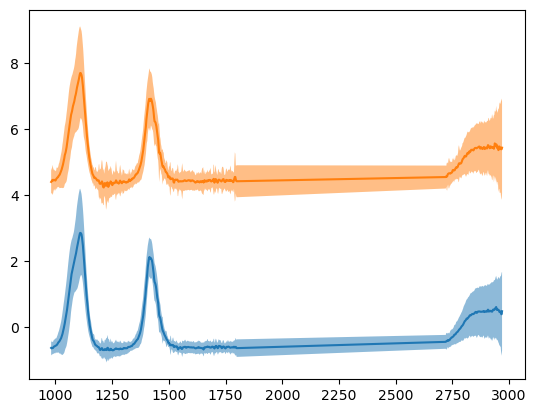

NaNO3


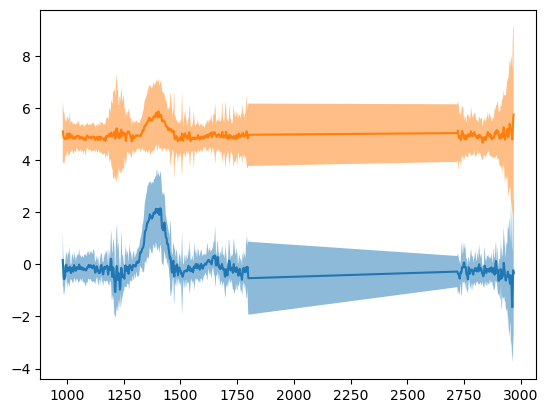

PE


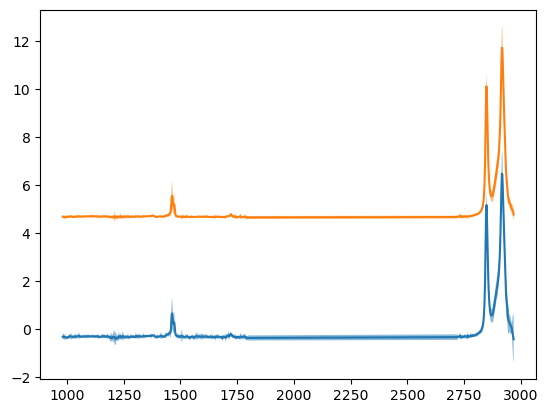

PP


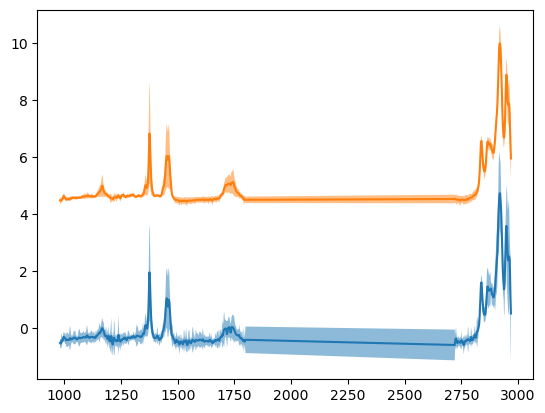

PSL


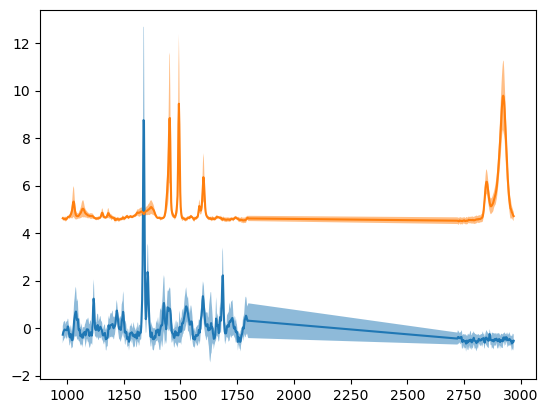

sucrose


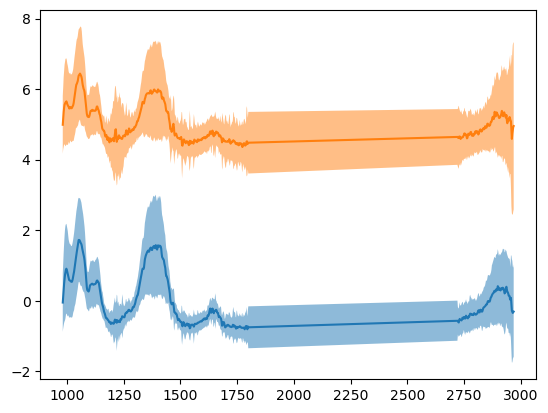

In [13]:
for i, p in enumerate(['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose']):
    print(p)
    
    y = preposs_data_ir.iloc[:,:-1].groupby('polymer').mean().iloc[i,:-2].T
    x = np.float64(preposs_data_ir.iloc[:,:-1].groupby('polymer').mean().iloc[i,:-2].index)
    std = preposs_data_ir.iloc[:,:-1].groupby('polymer').std().iloc[i,:-2].T
    y_low = np.array(y - std)
    y_up = np.array(y + std)
    _ = plt.plot(y)
    _ = plt.fill_between(x, y_low, y_up, alpha=0.5, label='Area between')
    
    
    y = preposs_data_ir_old.iloc[:,:-1].groupby('polymer').mean().iloc[i,:-2].T
    x = np.float64(preposs_data_ir_old.iloc[:,:-1].groupby('polymer').mean().iloc[i,:-2].index)
    std = preposs_data_ir_old.iloc[:,:-1].groupby('polymer').std().iloc[i,:-2].T
    y_low = np.array(y - std)
    y_up = np.array(y + std)

    _ = plt.plot(y+5)
    _ = plt.fill_between(x, y_low+5, y_up+5, alpha=0.5, label='Area between')
    
    _ = plt.show()

In [16]:
from sklearn.metrics import pairwise_distances
import seaborn as sns

In [17]:
preposs_data_ir_old.query('polymer == "PP"').iloc[:,:-4]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2951.0,2953.0,2955.0,2957.0,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0
334,-0.569751,-0.540007,-0.519020,-0.499186,-0.486757,-0.479796,-0.453323,-0.415724,-0.352926,-0.331123,...,3.399213,2.955994,2.491973,2.482463,2.608030,2.483403,2.133844,1.648478,1.207226,0.745776
335,-0.488017,-0.526054,-0.587063,-0.591989,-0.539375,-0.435620,-0.341458,-0.247296,-0.141716,-0.132502,...,3.572290,3.045681,2.484234,2.437068,2.501705,2.294047,2.054234,1.723632,1.271290,0.767003
336,-0.765059,-0.790770,-0.820661,-0.724810,-0.663088,-0.626561,-0.583663,-0.398222,-0.196350,-0.301247,...,2.230355,1.585041,1.116076,1.371354,1.701144,1.645376,0.941208,-0.130533,-0.563021,-0.595656
337,-0.549874,-0.569928,-0.586831,-0.578997,-0.557354,-0.518333,-0.461458,-0.401509,-0.358382,-0.365442,...,3.704365,3.461435,3.295175,3.338620,3.494057,3.527144,3.281229,2.793951,2.174716,1.535435
338,-0.454439,-0.456509,-0.456169,-0.458993,-0.459983,-0.455212,-0.446424,-0.434011,-0.427187,-0.430908,...,4.265442,3.737811,3.174721,2.797063,2.677791,2.643885,2.492819,2.138631,1.680064,1.235574
339,-0.583065,-0.580447,-0.590410,-0.593264,-0.584006,-0.578920,-0.563301,-0.539794,-0.529012,-0.527241,...,3.990568,3.575837,3.211134,3.034289,3.025454,3.005509,2.837834,2.419279,1.808830,1.241539
340,-0.426378,-0.438893,-0.467083,-0.491287,-0.494630,-0.484031,-0.465224,-0.431318,-0.413777,-0.432851,...,4.537724,4.186200,3.582454,3.124942,2.998914,2.904555,2.655496,2.244580,1.684564,1.162243
341,-0.509003,-0.500589,-0.532994,-0.511974,-0.467796,-0.463469,-0.432564,-0.347474,-0.282971,-0.287675,...,3.828400,3.303367,2.933183,2.803920,2.776693,2.700354,2.422320,2.091804,1.735923,1.282571
342,-0.429660,-0.408800,-0.385751,-0.367029,-0.336871,-0.374806,-0.374169,-0.366634,-0.367162,-0.376067,...,4.413268,3.854646,3.450047,3.111086,2.938030,3.016133,2.977792,2.362491,1.394366,0.683334
343,-0.447322,-0.453236,-0.447082,-0.432615,-0.427808,-0.423732,-0.423196,-0.416774,-0.403059,-0.400637,...,4.021060,3.763565,3.583498,3.636587,3.837162,3.919300,3.663359,3.069225,2.354030,1.679026


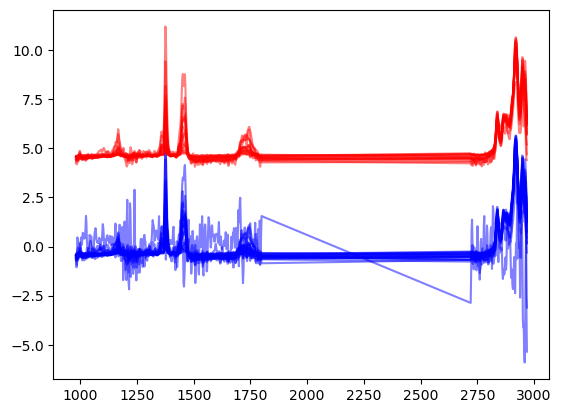

In [18]:
_ = plt.plot(preposs_data_ir.query('polymer == "PP"').iloc[:,:-4].T, color='blue', alpha=.5)

_ = plt.plot(preposs_data_ir_old.query('polymer == "PP"').iloc[:,:-4].T+5, color='red', alpha=.5)

In [33]:
preposs_data_ir.loc[np.round(pairwise_distances(preposs_data_ir_old.iloc[:,:-4],
                            preposs_data_ir.iloc[:,:-4]).min(0),2) < 5, :]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,polymer,id
22,0.070394,-0.480604,-0.614604,-0.283137,-0.235214,-0.277479,-0.372160,-0.422888,-0.499644,-0.498710,...,-0.051187,0.914206,0.877557,1.299312,1.118211,0.139590,0,0,NaNO3,SN_1
23,-0.336029,0.209883,0.792804,0.702125,-0.125878,-0.304515,-0.109902,-0.389135,0.438721,0.770576,...,1.510789,0.229382,-1.792890,-1.102939,2.830302,2.360417,0,0,NaNO3,SN_2
24,-1.162330,-0.556217,0.288206,-0.521388,-1.408890,-0.576921,0.277247,0.444378,0.363910,0.271956,...,-0.810542,-1.945834,-4.321832,-5.393378,-4.196270,-3.549222,0,0,NaNO3,SN_3
25,1.651365,-0.196968,-1.440150,-1.054299,-1.422165,-1.479478,-0.753259,0.435469,1.183177,0.461162,...,3.420001,-3.708942,-4.418552,-2.593685,-3.220022,-1.422245,0,0,NaNO3,SN_4
26,-0.543562,-0.852780,-1.155679,-0.251365,0.388791,0.167620,0.240279,0.167897,0.014979,-0.758529,...,-3.470033,-5.458449,-2.918310,0.072295,-1.508870,-3.788602,0,0,NaNO3,SN_5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
230,-0.394248,-0.394993,-0.341830,-0.420068,-0.559862,-0.509106,-0.410678,-0.424225,-0.461781,-0.511014,...,0.143393,0.151553,0.097257,0.244903,0.394957,0.220399,0,0,NH2SO4,AS_70
231,-0.591221,-0.573611,-0.630013,-0.641900,-0.627495,-0.686189,-0.700306,-0.702370,-0.696299,-0.674322,...,0.184412,0.319443,0.330383,0.295858,0.376717,0.501257,0,0,NH2SO4,AS_71
232,-0.844016,-0.822964,-0.818535,-0.830746,-0.840226,-0.835862,-0.813126,-0.785097,-0.799664,-0.765519,...,0.743179,0.742906,0.706567,0.451895,0.069237,0.044812,0,0,NH2SO4,AS_72
233,-0.805167,-0.811531,-0.812093,-0.804644,-0.799567,-0.804722,-0.810423,-0.814893,-0.819324,-0.814657,...,1.723448,1.717399,1.683766,1.639721,1.626468,1.649736,0,0,NH2SO4,AS_73


In [36]:
preposs_data_raman.loc[np.round(pairwise_distances(preposs_data_raman_old.iloc[:,:-4],
                            preposs_data_raman.iloc[:,:-4]).min(0),2) < 5, :]

np.round(pairwise_distances(preposs_data_raman_old.iloc[:,:-4],
                            preposs_data_raman.iloc[:,:-4]).min(0),2)

array([38.94, 12.06, 11.62, 31.75, 38.87, 28.84, 40.01, 40.68, 18.85,
       21.23, 23.95, 31.32, 24.24, 16.53, 20.99, 11.3 ,  8.72, 10.19,
       13.13,  7.76, 10.27,  7.86, 15.64, 12.1 , 11.76, 11.79, 45.44,
        5.16, 46.52, 40.94,  5.55,  8.01, 17.85,  9.31, 44.35, 44.03,
       31.23,  0.  ,  0.  ,  0.  ,  0.  ,  0.  ,  0.  ,  0.  ,  0.  ,
        0.  ,  0.  ,  0.  ,  0.  ,  0.  ,  0.  ,  0.  , 19.53,  0.  ,
        0.  ,  0.  , 13.39,  0.  , 13.9 , 14.92,  8.46,  0.  ,  3.09,
        2.97,  3.3 ,  3.34,  3.04,  3.34,  4.58,  3.8 ,  3.18,  3.15,
       14.75,  3.83,  3.71,  4.1 ,  4.27,  3.54,  3.93,  3.94,  4.5 ,
        4.55, 34.87, 18.85, 15.15, 10.26, 17.13, 13.98,  6.61,  6.8 ,
       11.86,  6.86,  8.63, 15.34, 10.62, 11.38, 14.71, 12.48,  7.63,
       10.77,  8.23, 10.3 , 15.22, 11.7 , 19.88, 15.71, 10.14, 26.81,
        8.16, 21.46,  7.05,  7.44,  8.86, 15.3 ,  9.7 , 12.15,  8.59,
       10.81, 13.39, 10.41, 12.22, 12.83,  7.02,  7.46,  6.74, 39.01,
       13.77, 15.67,

In [38]:
preposs_data_raman

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
0,-0.161330,-0.161060,-0.147570,-0.132859,-0.138004,-0.159994,-0.213961,-0.259729,-0.300238,-0.355538,...,-0.331141,-0.315765,-0.298202,-0.277088,-0.287371,-0.314905,0,0,PSL,PS_1
1,-0.200846,-0.196675,-0.214777,-0.235822,-0.233476,-0.256515,-0.327742,-0.355576,-0.355576,-0.274907,...,-0.355576,-0.355576,-0.334642,-0.279731,-0.253052,-0.241887,0,0,PSL,PS_2
2,-0.323219,-0.242770,-0.293719,-0.358726,-0.248153,-0.189625,-0.229889,-0.288456,-0.358764,-0.303403,...,-0.367664,-0.367664,-0.367664,-0.367664,-0.367664,-0.367664,0,0,PSL,PS_3
3,-0.223385,-0.575258,-0.425383,-0.205304,-0.467829,-0.570510,-0.369764,-0.229587,-0.128261,-0.379268,...,-0.614505,-0.398424,-0.288712,-0.351648,-0.472793,-0.625923,0,0,PSL,PS_4
4,0.229119,-0.150276,-0.109249,0.045177,0.415732,0.454005,-0.138489,-0.468662,-0.630572,-0.651068,...,-0.651068,-0.651068,-0.651068,-0.651068,-0.651068,-0.651068,0,0,PSL,PS_5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
230,-0.109193,-0.114081,-0.051795,0.008843,-0.120742,-0.205616,-0.205616,-0.179509,-0.136654,-0.067922,...,-0.084663,-0.089691,-0.117579,-0.182570,-0.205616,-0.205616,0,0,NH2SO4,AS_70
231,-0.207049,-0.207049,-0.155444,-0.098419,-0.111520,-0.123683,-0.134067,-0.128425,-0.112505,-0.064351,...,-0.203120,-0.169518,-0.161535,-0.195135,-0.207049,-0.207049,0,0,NH2SO4,AS_71
232,-0.030249,-0.019697,-0.015052,-0.009409,0.022660,0.052368,0.077593,0.050568,-0.009972,-0.093266,...,-0.167942,-0.167942,-0.167942,-0.167942,-0.167942,-0.167942,0,0,NH2SO4,AS_72
233,-0.106790,-0.108438,-0.105830,-0.101529,-0.088838,-0.081034,-0.082508,-0.093636,-0.110957,-0.128042,...,-0.142326,-0.138729,-0.135679,-0.133517,-0.134157,-0.136335,0,0,NH2SO4,AS_73


In [34]:
preposs_data_ir.loc[np.round(pairwise_distances(preposs_data_ir_old.iloc[:,:-4],
                            preposs_data_ir.iloc[:,:-4]).min(0),2) > 5, :]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,polymer,id
0,-0.251625,-0.255108,-0.323209,-0.357295,-0.288929,-0.231149,-0.277989,-0.365222,-0.364379,-0.329271,...,-0.401221,-0.446185,-0.454129,-0.473735,-0.473678,-0.452926,0,0,PSL,PS_1
1,-0.191317,-0.354169,-0.306084,-0.080888,-0.099344,-0.272356,-0.263308,-0.169747,-0.278567,-0.357928,...,-0.450236,-0.460589,-0.446044,-0.475673,-0.455626,-0.340559,0,0,PSL,PS_2
2,-0.478467,-0.233657,-0.178455,-0.150699,-0.035209,-0.018803,0.016500,0.074853,0.028169,-0.063124,...,-0.405724,-0.446773,-0.415728,-0.349406,-0.429709,-0.474209,0,0,PSL,PS_3
3,-0.992043,-0.571662,-0.236577,-0.405455,-0.224910,0.162383,0.073391,-0.193367,-0.608756,-1.103371,...,-0.314642,-0.530756,-1.042570,-0.830783,-0.555936,-0.491079,0,0,PSL,PS_4
4,0.227219,0.188838,-0.280390,-0.579778,-0.373598,-0.361577,-0.084783,0.816399,0.389333,-0.478769,...,-1.138533,-0.999645,-0.872286,-0.996456,-1.414181,-1.404357,0,0,PSL,PS_5
5,-0.148260,-0.128715,-0.054244,-0.098409,0.071300,0.306848,0.197096,-0.091282,-0.315895,-0.327650,...,-0.625215,-0.789953,-0.178638,0.039950,-0.195705,-0.299460,0,0,PSL,PS_6
6,-0.175667,-0.626536,0.107278,0.465438,-0.662256,-1.152665,-0.395725,0.112315,0.035571,0.269018,...,-1.199968,-1.461407,-0.801971,-0.655173,-1.144319,-0.392419,0,0,PSL,PS_7
7,-1.007497,-0.304731,0.171394,0.399070,0.841844,0.826006,0.201761,-0.699389,-0.365546,0.314342,...,-0.890151,-0.927325,-0.923629,-1.262222,-1.482080,-0.935792,0,0,PSL,PS_8
8,-0.603212,-0.708043,-0.582085,-0.409057,-0.447684,-0.378137,-0.076378,0.020571,0.054947,-0.183497,...,-0.526553,-0.523845,-0.534875,-0.544747,-0.601207,-0.444037,0,0,PSL,PS_9
9,-0.671894,-0.002658,0.228872,0.139752,-0.048713,-0.389413,-0.436421,-0.391916,0.067375,0.124337,...,-0.547130,-0.646726,-0.719860,-0.793999,-0.829055,-0.811240,0,0,PSL,PS_10


<AxesSubplot: >

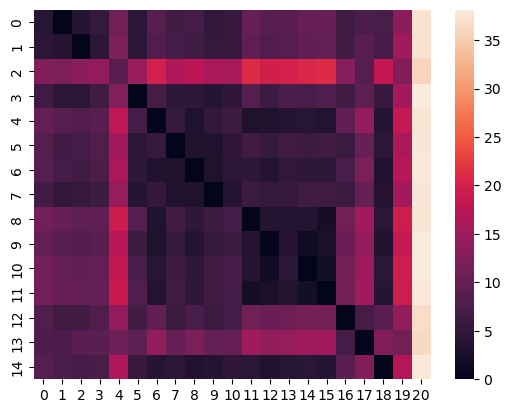

In [22]:
sns.heatmap(pairwise_distances(preposs_data_ir_old.query('polymer == "PP"').iloc[:,:-4],
preposs_data_ir.query('polymer == "PP"').iloc[:,:-4]))

<AxesSubplot: >

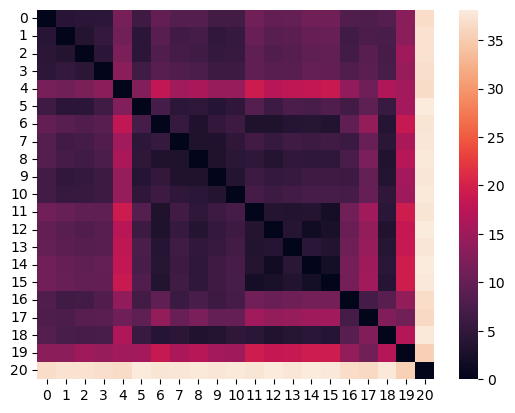

In [200]:
p = "PP"
sns.heatmap(pairwise_distances(preposs_data_ir.query('polymer == @p').iloc[:,:-4]))

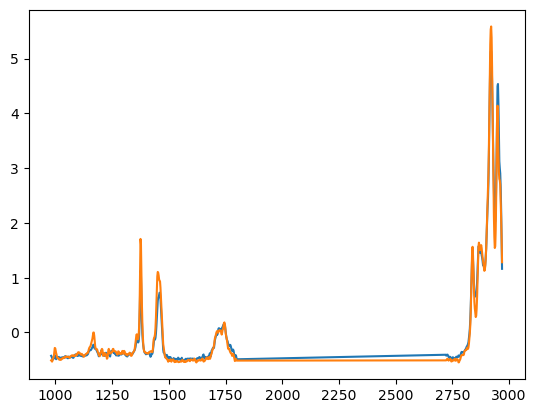

In [210]:
p = "PP"
_ = plt.plot(preposs_data_ir.query('polymer == @p').iloc[:,:-4].loc[pairwise_distances(preposs_data_ir.query('polymer == @p').iloc[:,:-4]).mean(1)<8,:].T)



In [211]:
p = "PP"
ids_rem = list(preposs_data_ir.query('polymer == @p').loc[pairwise_distances(preposs_data_ir.query('polymer == @p').iloc[:,:-4]).mean(1)>8,'id'])
ids_rem

['PP_1',
 'PP_2',
 'PP_3',
 'PP_4',
 'PP_5',
 'PP_6',
 'PP_7',
 'PP_8',
 'PP_11',
 'PP_12',
 'PP_13',
 'PP_14',
 'PP_15',
 'PP_16',
 'PP_17',
 'PP_18',
 'PP_19',
 'PP_20',
 'PP_21']

In [202]:
preposs_data_ir_old.query('polymer == "PSL"').iloc[:,:]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,polymer,id
0,0.068218,0.005559,0.002129,0.096833,0.166458,0.244026,0.274505,-0.042581,-0.167374,0.065576,...,-0.343677,-0.415935,-0.42848,-0.383494,-0.431358,-0.377201,0,0,PSL,PSL_18
1,-0.183220,-0.171008,-0.234405,-0.244308,-0.120008,-0.003775,0.043415,0.010371,0.000206,0.004902,...,-0.386201,-0.357189,-0.35657,-0.345452,-0.333777,-0.303500,0,0,PSL,PSL_20


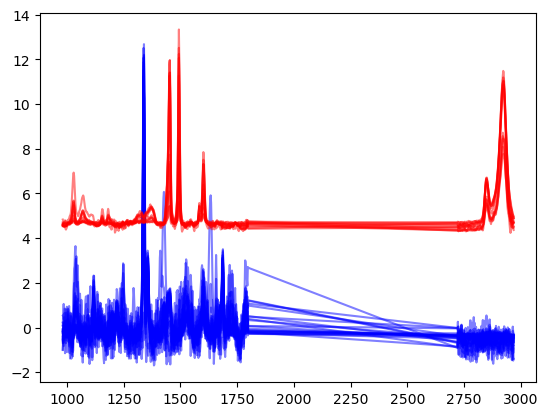

In [15]:
p = "PSL"
_ = plt.plot(preposs_data_ir.query('polymer == @p').iloc[:,:-4].T, color='blue', alpha=.5)

_ = plt.plot(preposs_data_ir_old.query('polymer == @p').iloc[:,:-4].T+5, color='red', alpha=.5)

<AxesSubplot: >

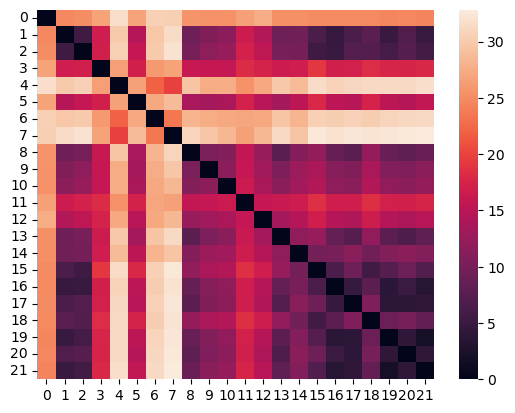

In [204]:
p = "PSL"
sns.heatmap(pairwise_distances(preposs_data_ir.query('polymer == @p').iloc[:,:-4]))

In [212]:
p = "PSL"
ids_rem = ids_rem + list(preposs_data_ir.query('polymer == @p').loc[pairwise_distances(preposs_data_ir.query('polymer == @p').iloc[:,:-4]).mean(1)>13,'id'])


In [213]:
ids_rem

['PP_1',
 'PP_2',
 'PP_3',
 'PP_4',
 'PP_5',
 'PP_6',
 'PP_7',
 'PP_8',
 'PP_11',
 'PP_12',
 'PP_13',
 'PP_14',
 'PP_15',
 'PP_16',
 'PP_17',
 'PP_18',
 'PP_19',
 'PP_20',
 'PP_21',
 'PS_1',
 'PS_3',
 'PS_4',
 'PS_5',
 'PS_6',
 'PS_7',
 'PS_8',
 'PS_9',
 'PS_10',
 'PS_11',
 'PS_12',
 'PS_13',
 'PS_14',
 'PS_15',
 'PS_16',
 'PS_19']

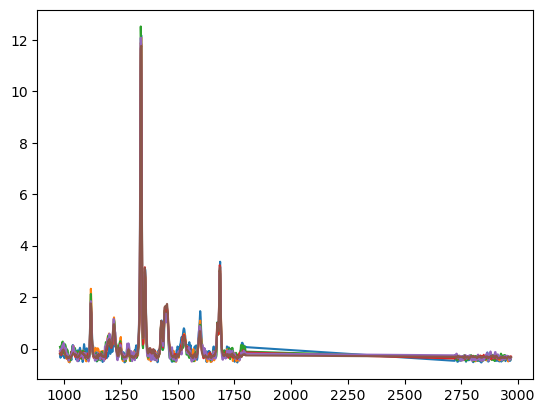

In [207]:
p = "PSL"
_ = plt.plot(preposs_data_ir.query('polymer == @p').iloc[:,:-4].loc[pairwise_distances(preposs_data_ir.query('polymer == @p').iloc[:,:-4]).mean(1)<13,:].T)


NH2SO4


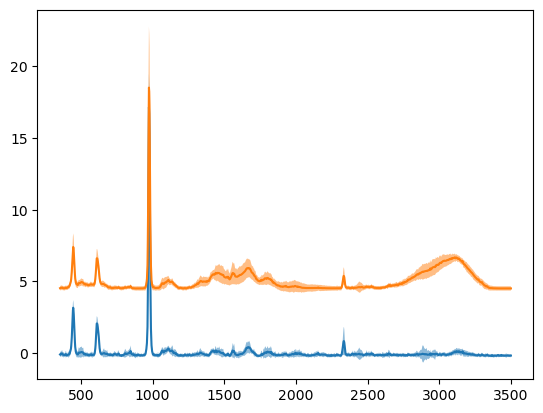

NaNO3


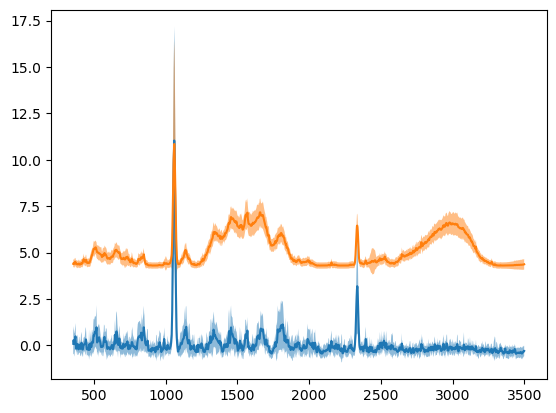

PE


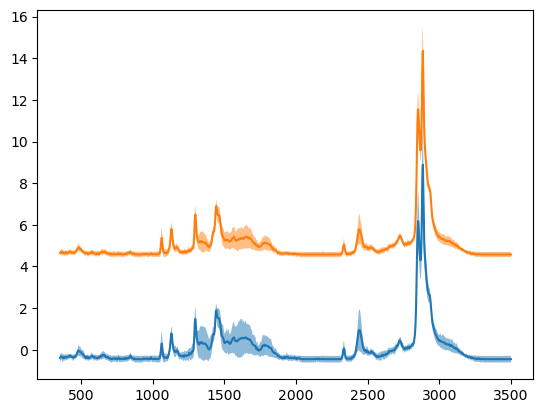

PP


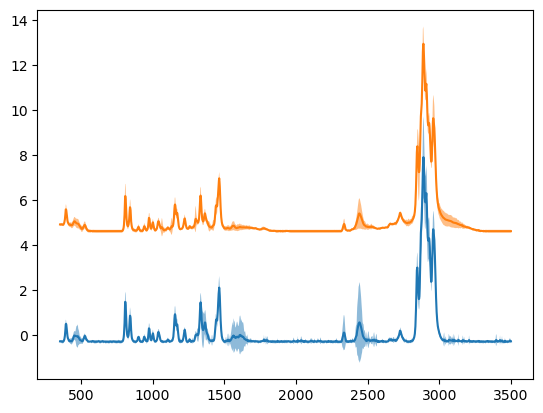

PSL


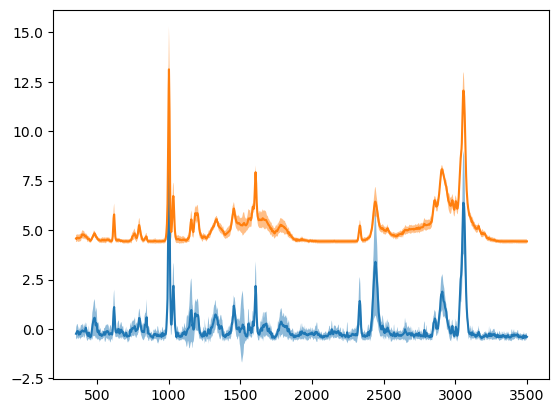

sucrose


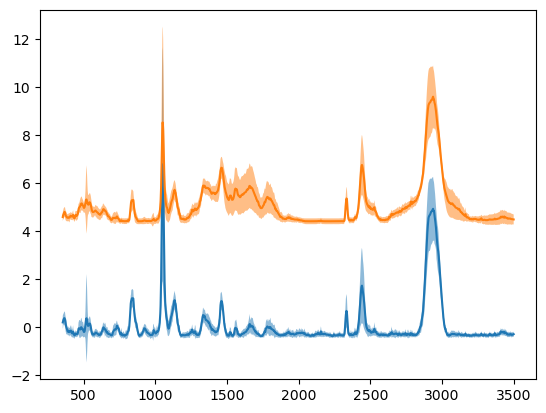

In [39]:
for i, p in enumerate(['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose']):
    print(p)
    
    y = preposs_data_raman.iloc[:,:-1].groupby('polymer').mean().iloc[i,:-2].T
    x = np.float64(preposs_data_raman.iloc[:,:-1].groupby('polymer').mean().iloc[i,:-2].index)
    std = preposs_data_raman.iloc[:,:-1].groupby('polymer').std().iloc[i,:-2].T
    y_low = np.array(y - std)
    y_up = np.array(y + std)
    _ = plt.plot(y)
    _ = plt.fill_between(x, y_low, y_up, alpha=0.5, label='Area between')
    
    
    y = preposs_data_raman_old.iloc[:,:-1].groupby('polymer').mean().iloc[i,:-2].T
    x = np.float64(preposs_data_raman_old.iloc[:,:-1].groupby('polymer').mean().iloc[i,:-2].index)
    std = preposs_data_raman_old.iloc[:,:-1].groupby('polymer').std().iloc[i,:-2].T
    y_low = np.array(y - std)
    y_up = np.array(y + std)

    _ = plt.plot(y+5)
    _ = plt.fill_between(x, y_low+5, y_up+5, alpha=0.5, label='Area between')
    
    _ = plt.show()

NH2SO4


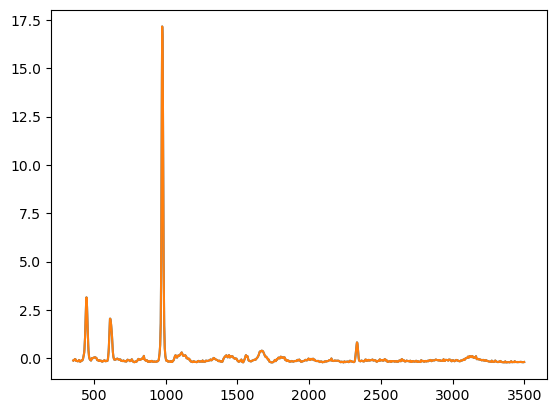

NaNO3


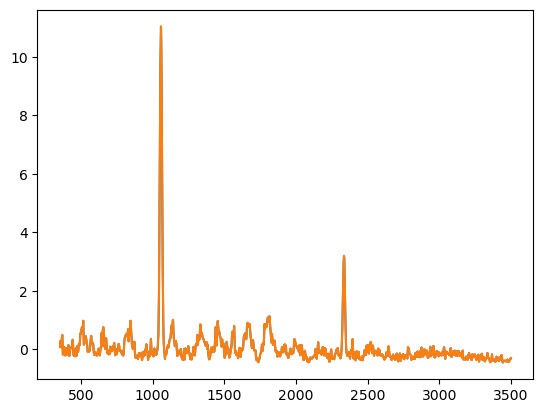

PE


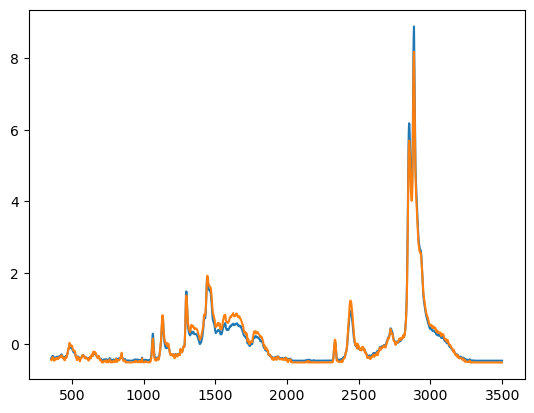

PP


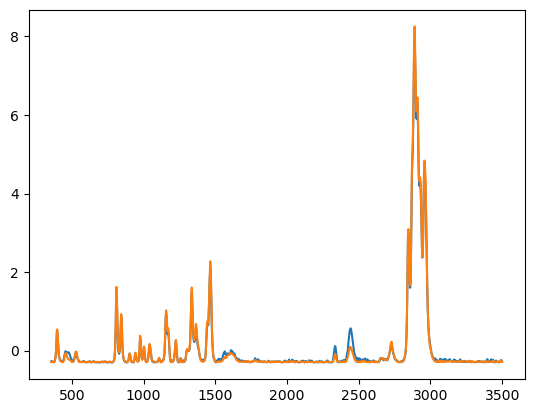

PSL


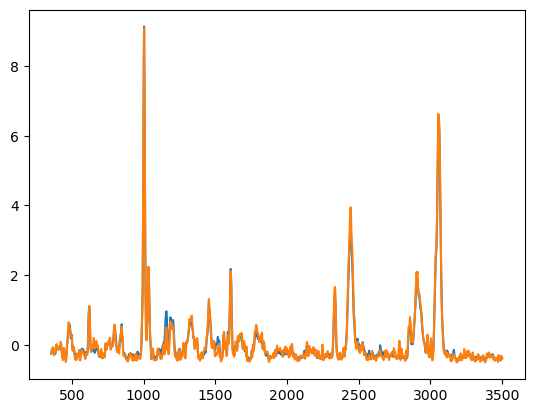

sucrose


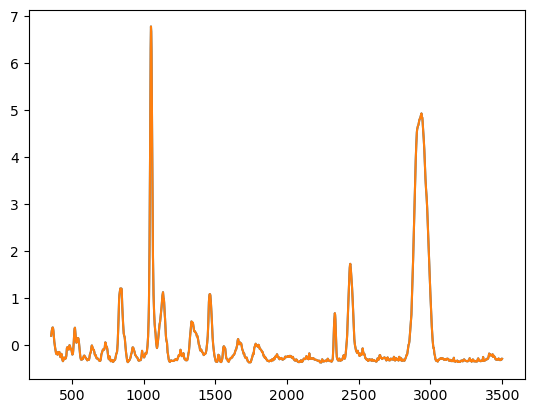

In [122]:
for i, p in enumerate(['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose']):
    print(p)
    _ = plt.plot(preposs_data_raman.iloc[:,:-1].groupby('polymer').mean().iloc[i,:-2].T)
    _ = plt.plot(preposs_data_raman_old.iloc[:,:-1].groupby('polymer').mean().iloc[i,:-2].T)
    _ = plt.show()

# Library

In [3]:
#directory_name = '/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
directory_name = 'MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
ir_export_filename =  "no_interpolate_equiv_ir.csv"  ###enter your desired export Raman csv filename, in quotes
raman_export_filename =  "no_interpolate_equiv_raman.csv"  ###enter your desired export Raman csv filename, in quotes
file_list_tmp = [] ###option to list out the files you want included. if left as-is, all files in directory will be included.

path = 'Reference_library_reb/'
dirs = os.listdir(path)
dirs = [x for x in dirs if x not in ['.DS_Store', 'Archive for reference data', 'Processed']]

file_list = []
for d in dirs:
    #print(os.listdir(path + d + '/Data/Processed/mIRage OPTIR+Raman/'))
    path_2 = path + d + '/Data/Processed/mIRage OPTIR+Raman/'
    dirs_2 = os.listdir(path_2)
    #file_list = file_list + [path_2 + dd for dd in dirs_2 if dd[-4:] == "xlsx"]
    file_list = file_list + [path_2 + dd for dd in dirs_2 if (dd[-9:] == "data.xlsx" or dd[-12:] == "spectra.xlsx")]
file_list = file_list + [d + '/' + dd for dd in dirs_2 if (dd[-9:] == "data.xlsx" or dd[-12:] == "spectra.xlsx")]

polymer_list = np.array(['sucrose', 'PE', 'PSL', 'NaNO3', 'NH2SO4', 'PP'])

wn_list = []
df_list = []
for i, f in enumerate(file_list):
    df = pd.read_excel(f, sheet_name=None)#['Raman', 'Raman spectra']
    print(f)
    if 'Raman' in df.keys():
        df_raman = df['Raman']
    elif 'Raman spectra' in df.keys():
        df_raman = df['Raman spectra']
    df_raman.columns = ['wavenumber'] + list(range(df_raman.shape[1]-1))#.set_index('X value [cmâ»Â¹]')
    df_raman = df_raman.set_index('wavenumber')
    df_raman = df_raman.T.reset_index(drop=True)
    df_raman['polymer'] = polymer_list[[p in f for p in polymer_list]][0]#polymer[i]
    df_raman['map_x'] = 0
    df_raman['map_y'] = 0
    
    if 'O-PTIR' in df.keys():
        df_ir = df['O-PTIR']
    elif 'PTIR spectra' in df.keys():
        df_ir = df['PTIR spectra']
    df_ir.columns = ['wavenumber'] + list(range(df_ir.shape[1]-1))#.set_index('X value [cmâ»Â¹]')
    df_ir = df_ir.set_index('wavenumber')
    df_ir = df_ir.T.reset_index(drop=True)
    df_ir['polymer'] = polymer_list[[p in f for p in polymer_list]][0]#polymer[i]
    df_ir['map_x'] = 0
    df_ir['map_y'] = 0
    
    df_list.append([df_ir,df_raman])
    
pol_table = pd.DataFrame({'file':[polymer_list[[p in f for p in polymer_list]][0] for f in file_list]})
args.si_peak = np.array([520.0]*len(df_list))

raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = df_list, transpose = True)


Reference_library_reb/20230708 0.05 M sucrose/Data/Processed/mIRage OPTIR+Raman/20240509_50mMsucrose_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230423 1.0 and 3.0 um PSL/Data/Processed/mIRage OPTIR+Raman/20230424_1and3umPSL_allccdata.xlsx
Reference_library_reb/20230708 0.05 M NaNO3/Data/Processed/mIRage OPTIR+Raman/20240509_50mMNaNO3_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230707 200 to 9900 nm PE EtOH iced atomized/Data/Processed/mIRage OPTIR+Raman/20230707_200to9900nmPE_EtOHiced_atomized_mIRage_allccdata.xlsx
Reference_library_reb/20230708 0.05 M NH2SO4/Data/Processed/mIRage OPTIR+Raman/20240509_50mMNH42SO4_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230906 1 to 5 um PP 50-50 EtOH-Omni 2 min sonication iced/Data/Processed/mIRage OPTIR+Raman/20230906_1to5umPP_2minsonic_iced_30minMPSstg2_allspectra.xlsx


In [17]:
#df_ir_all = pd.concat([x[0] for x in df_list], axis=0)

#for i in range(len(df_list)):
#    df_list[i][1].columns = df_list[0][1].columns
#df_raman_all = pd.concat([x[1] for x in df_list], axis=0)

#idx_ir_in_lib = np.logical_or([x in np.array(ids_lib) for x in df_ir_all['id']],
#                              [x not in material_list for x in df_ir_all['polymer']])

#idx_raman_in_lib = np.logical_or([x in np.array(ids_lib_r) for x in df_raman_all['id']],
#                                 [x not in material_list for x in df_raman_all['polymer']])

#df_raman_all['id'] = id_list
#df_ir_all['id'] = id_list

#df_raman_all['maddie_screened'] = 'no'
#df_ir_all['maddie_screened'] = 'no'

#df_raman_all.loc[idx_raman_in_lib,'maddie_screened'] = 'yes'
#df_ir_all.loc[idx_ir_in_lib,'maddie_screened'] = 'yes'

#df_ir_all.to_csv('multiview_hqi_cp/reference_library_original_ir.csv')
#df_raman_all.to_csv('multiview_hqi_cp/reference_library_original_raman.csv')

In [7]:
id_list = np.array(label_list, dtype='<U15')
for poly in np.unique(label_list):
    n = sum(np.array(label_list) == poly)
    id_list[id_list==poly] = [poly+'_'+str(i+1) for i in range(n)]

In [9]:
material_list = ['PSL', 'PE', 'PP']

material_sheets = ['PSL', 'PE', 'PP']
df_st_in_lib_ir_list = []
for mat, sheet in zip(material_list, material_sheets):
    df_st_in_lib_ir = pd.read_excel('gloves_contamination/MEC_04_017_Raman_and_PTIR_PSL_PP_PE_Library_Sorted.xlsx', sheet_name=sheet)
    df_st_in_lib_ir = df_st_in_lib_ir.iloc[:-1,:2]#['Number']
    df_st_in_lib_ir['id'] = [mat+ '_' + str(int(x)) for x in df_st_in_lib_ir['ID']]
    df_st_in_lib_ir = df_st_in_lib_ir.loc[:,['id', 'PTIR']]
    df_st_in_lib_ir.columns = ['id', 'in_library']
    df_st_in_lib_ir_list.append(df_st_in_lib_ir)    
df_st_in_lib_ir = pd.concat(df_st_in_lib_ir_list, axis=0)
df_st_in_lib_ir = df_st_in_lib_ir.query('in_library == 1').reset_index(drop=True)
ids_lib = df_st_in_lib_ir['id']

df_st_in_lib_raman_list = []
for mat, sheet in zip(material_list, material_sheets):
    df_st_in_lib_raman = pd.read_excel('gloves_contamination/MEC_04_017_Raman_and_PTIR_PSL_PP_PE_Library_Sorted.xlsx', sheet_name=sheet)
    df_st_in_lib_raman = df_st_in_lib_raman.iloc[:-1,[0,3]]#['Number']
    df_st_in_lib_raman['id'] = [mat+ '_' + str(int(x)) for x in df_st_in_lib_raman['ID']]
    df_st_in_lib_raman = df_st_in_lib_raman.loc[:,['id', 'Raman']]
    df_st_in_lib_raman.columns = ['id', 'in_library']
    df_st_in_lib_raman_list.append(df_st_in_lib_raman)
df_st_in_lib_raman = pd.concat(df_st_in_lib_raman_list, axis=0)
df_st_in_lib_raman = df_st_in_lib_raman.query('in_library == 1').reset_index(drop=True)

ids_lib_r = df_st_in_lib_raman['id']


In [32]:
df_st_in_lib = pd.read_excel('multiview_hqi_cp/data_new/20250523_RP_CCOPTIR_referencelibrary_filtercomparison.xlsx',
              sheet_name='MVCP')
ids_lib = df_st_in_lib.query('rebecca_PTIR_screened=="yes"')['id'].to_numpy()
ids_lib_r = df_st_in_lib.query('rebecca_Raman_screened=="yes"')['id'].to_numpy()

In [44]:
material_list = np.unique([x.split('_')[0] for x in ids_lib])

In [50]:
preposs_data_raman_old = pd.DataFrame(raman_final)
preposs_data_raman_old.columns = XX_raman
preposs_data_raman_old = pd.concat([preposs_data_raman_old, coords], axis=1)
preposs_data_raman_old['polymer'] = label_list
preposs_data_raman_old['id'] = id_list
#preposs_data_raman_old = preposs_data_raman_old.merge(df_st_in_lib_raman).drop('in_library',axis=1).reset_index(drop=True)
preposs_data_raman_old = preposs_data_raman_old.query('id in @ids_lib_r or polymer not in @material_list').reset_index(drop=True)
preposs_data_raman_old.to_csv('multiview_hqi_cp/processed_data_new/rebecca_data_raman_final_specy.csv')

preposs_data_ir_old = pd.DataFrame(ir_final)
preposs_data_ir_old.columns = XX_ir
preposs_data_ir_old = pd.concat([preposs_data_ir_old, coords], axis=1)
preposs_data_ir_old['polymer'] = label_list
preposs_data_ir_old['id'] = id_list
#preposs_data_ir_old = preposs_data_ir_old.merge(df_st_in_lib_ir).drop('in_library',axis=1).reset_index(drop=True)
preposs_data_ir_old = preposs_data_ir_old.query('id in @ids_lib or polymer not in @material_list').reset_index(drop=True)
preposs_data_ir_old.to_csv('multiview_hqi_cp/processed_data_new/rebecca_data_ir_final.csv')


In [46]:
preposs_data_raman_old

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
0,-0.360185,-0.378175,-0.273872,-0.156594,-0.203969,-0.249150,-0.290166,-0.343289,-0.404177,-0.489183,...,-0.741678,-0.620830,-0.592120,-0.712959,-0.755810,-0.755810,0,0,sucrose,sucrose_1
1,-0.583070,-0.462218,-0.367239,-0.286599,-0.302948,-0.299441,-0.258242,-0.262459,-0.295807,-0.476042,...,-0.649835,-0.649835,-0.649835,-0.649835,-0.649835,-0.649835,0,0,sucrose,sucrose_2
2,-0.489462,-0.357636,-0.354522,-0.373786,-0.318909,-0.287341,-0.300022,-0.329140,-0.368803,-0.360527,...,-0.562291,-0.562291,-0.524984,-0.427121,-0.455576,-0.553439,0,0,sucrose,sucrose_3
3,-0.534808,-0.429173,-0.319137,-0.214650,-0.184506,-0.140560,-0.070414,-0.029642,-0.007712,-0.102542,...,-0.414286,-0.395483,-0.429819,-0.550406,-0.593167,-0.593167,0,0,sucrose,sucrose_6
4,-0.218156,-0.106056,-0.093650,-0.100681,-0.074206,-0.057225,-0.058265,-0.059023,-0.059601,-0.147018,...,-0.323221,-0.319960,-0.316570,-0.312970,-0.301601,-0.285964,0,0,sucrose,sucrose_7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
301,-0.070290,-0.055690,-0.055487,-0.060189,-0.083916,-0.100894,-0.105059,-0.104582,-0.101127,-0.086683,...,-0.402942,-0.402942,-0.402942,-0.402942,-0.402942,-0.402942,0,0,PP,PP_84
302,-0.072507,-0.066909,-0.064383,-0.062916,-0.065657,-0.067472,-0.067532,-0.067720,-0.067991,-0.070663,...,-0.341669,-0.341669,-0.341669,-0.341669,-0.341669,-0.341669,0,0,PP,PP_90
303,-0.025930,-0.048931,-0.040949,-0.026553,-0.018326,-0.017699,-0.031500,-0.046641,-0.062640,-0.054032,...,-0.384511,-0.384511,-0.384511,-0.384511,-0.384511,-0.384511,0,0,PP,PP_92
304,-0.054903,-0.076317,-0.053542,-0.023370,-0.021893,-0.022687,-0.027793,-0.033593,-0.039837,-0.044357,...,-0.391231,-0.391231,-0.391231,-0.391231,-0.391231,-0.391231,0,0,PP,PP_93


In [47]:
preposs_data_ir_old

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,polymer,id
0,-0.447035,-0.421266,-0.467836,-0.372833,-0.145153,0.130042,0.189127,0.155498,0.205391,0.153876,...,-0.687966,-0.724311,-0.715632,-0.514595,-0.280458,-0.347723,0,0,sucrose,sucrose_1
1,-0.815085,-0.512456,-0.297874,-0.198960,-0.148931,-0.163417,-0.028107,0.146969,0.169685,0.146503,...,-0.666376,-0.867979,-0.927873,-0.614046,0.066000,0.134807,0,0,sucrose,sucrose_2
2,-0.520710,-0.445017,-0.352656,-0.253250,-0.105821,-0.032574,-0.047475,0.040878,0.113861,0.036063,...,-0.231158,-0.101210,-0.176790,-0.569805,-0.798102,-0.838369,0,0,sucrose,sucrose_3
3,-0.402060,-0.424283,-0.528735,-0.530170,-0.446972,-0.325313,-0.381953,-0.499918,-0.383397,-0.093098,...,0.899960,1.247222,1.547973,1.412458,0.660978,-0.348765,0,0,sucrose,sucrose_6
4,-0.132373,0.052544,0.249514,0.420353,0.532474,0.611563,0.665630,0.695106,0.699343,0.662427,...,-0.508035,-0.522078,-0.618666,-0.679660,-0.674599,-0.661172,0,0,sucrose,sucrose_7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
226,-0.403715,-0.406475,-0.379061,-0.366200,-0.377605,-0.369202,-0.352946,-0.356614,-0.354155,-0.352132,...,3.754442,3.796968,3.524448,2.828617,1.970687,1.308557,0,0,PP,PP_77
227,-0.358557,-0.361365,-0.376554,-0.503994,-0.526841,-0.525094,-0.477289,-0.322778,-0.217072,-0.212908,...,3.239374,3.490094,3.525187,2.243920,0.892669,0.465358,0,0,PP,PP_84
228,-0.649432,-0.640148,-0.584204,-0.568430,-0.634238,-0.666232,-0.597424,-0.500822,-0.487258,-0.489202,...,1.709406,1.325345,0.969826,0.667303,0.368518,0.186478,0,0,PP,PP_90
229,-0.686427,-0.606687,-0.574666,-0.592168,-0.568527,-0.537234,-0.478637,-0.391549,-0.351008,-0.323794,...,1.839385,1.781715,1.445687,0.937241,0.251156,-0.307574,0,0,PP,PP_92
